# **PROJETO TMBA - Google Play Store App**

### **Projeto desenvolvido por:**
- Débora Jesus, nº2250064
- João Vasques, nº2250055
- Rui Filipe Parada, nº2211025

---




O presente projeto tem como objetivo realizar uma análise de sentimentos e modelação de dados textuais provenientes de reviews de aplicações da Google Play Store. Numa primeira fase, conduzimos uma análise exploratória (EDA) detalhada para compreender a distribuição das aplicações, a polaridade e a subjetividade dos comentários. Posteriormente, aplicamos um pipeline rigoroso de pré-processamento de texto para limpar e normalizar os dados, preparando-os para a fase de extração de features e treino de modelos de classificação. No final, avaliamos qual o melhor modelo a implementar.


| _Feature_ | _Descrição_ |
| :--- | :--- |
| _App_ | Identifica a aplicação específica da google play (serve como id) |
| _Translated_Review_ | Comentários/Reviews feitos pelos utilizadores (traduzidos para inglês) |
| _Sentiment_ | Classificação categórica de sentimento dos comentários/reviews |
| _Sentiment_Polarity_ | Valor numérico que quantifica o "positivismo" e "negativismo" do comentário/review (escala de -1 a 1) |
| _Sentiment_Subjetivity_ | Valor numérico que quantifica o quão objetivo ou subjetivo é o comentário/review (escala 0 a 1)|

---

# **1. Imports and Data Upload**

In [ ]:
# Instalação de bibliotecas adicionais
!pip install contractions
!pip install emoji
!pip install wordcloud

In [ ]:
# Imports principais
from google.colab import drive
from google.colab import files
import pandas as pd
import numpy as np
import io

# Processamento de linguagem natural
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, words
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from nltk.corpus import words as nltk_words

# Visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Tratamento de texto
import contractions
import emoji
import string
import re
from html import unescape
from sklearn.utils.class_weight import compute_class_weight

# Aprendizagem automática
from sklearn.utils import resample
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Algoritmos de classificação
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
import lightgbm as lgb
from lightgbm import LGBMClassifier

import warnings
import shap

In [ ]:
# Downloads necessários do NLTK
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('words')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Package words is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [ ]:
# Upload do dataset (em csv)

uploaded = files.upload()

df = pd.read_csv(io.BytesIO(uploaded['google_play_store_apps.csv']), sep=',')

Saving google_play_store_apps.csv to google_play_store_apps.csv


In [ ]:
df.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
3,10 Best Foods for You,Best idea us,Positive,1.00,0.300000
4,10 Best Foods for You,Best way,Positive,1.00,0.300000


# **2. Análise Exploratória dos Dados**


In [ ]:
# Mostrar todas as colunas existentes no DataFrame
pd.set_option('display.max_columns', None)

# Evitar que o pandas distribua colunas por várias linhas na visualização
pd.set_option('display.expand_frame_repr', False)

# Evitar quebra de colunas em várias linhas durante a visualização
pd.set_option('display.expand_frame_repr', False)

# Mostrar o conteúdo completo das colunas textuais sem truncar texto
pd.set_option('display.max_colwidth', None)

## **2.1. Análise do Dataset**

In [ ]:
# Visualizar as 10 primeiras linhas do novo DataFrame review_df
display(df.head(10))

# Mostrar informação estrutural do DataFrame
print("--------------------------------")
print("Colunas do DataFrame:", list(df.columns))
print("--------------------------------")
print("Número total de reviews:", len(df))

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,"I like eat delicious food. That's I'm cooking food myself, case ""10 Best Foods"" helps lot, also ""Best Before (Shelf Life)""",Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
3,10 Best Foods for You,Best idea us,Positive,1.00,0.300000
4,10 Best Foods for You,Best way,Positive,1.00,0.300000
5,10 Best Foods for You,Amazing,Positive,0.60,0.900000
6,10 Best Foods for You,"Looking forward app,",Neutral,0.00,0.000000
7,10 Best Foods for You,It helpful site ! It help foods get !,Neutral,0.00,0.000000
8,10 Best Foods for You,good you.,Positive,0.70,0.600000
9,10 Best Foods for You,"Useful information The amount spelling errors questions validity information shared. Once fixed, 5 stars given.",Positive,0.20,0.100000


--------------------------------
Colunas do DataFrame: ['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']
--------------------------------
Número total de reviews: 37427


In [ ]:
### ---ANÁLISE DO DATASET--- ###

print("----- ANÁLISE DO DATASET -----\n")

# Forma do dataset
print("----- Forma do dataset -----\n")
print(f"df shape:   {df.shape}\n")

# Info do dataset
print("----- Informações do dataset -----\n")
print(f" df info:   {df.info()}\n")

# Tipos de dados
print("----- Tipo de dados do dataset -----\n")
print("df dtypes:")
print(df.dtypes, "\n")

# Estatísticas descritivas
print("----- Dados descritivos do dataset -----\n")
print("df describe:")
print(df.describe(), "\n")

# Duplicados
print("----- Duplicados do dataset -----\n")
print(f"df duplicados:   {df.duplicated().sum()}\n")

# Nulos por coluna
print("----- Nulos por coluna -----\n")
print("df nulos por coluna:")
print(df.isnull().sum(), "\n")

# Total de nulos
print("----- Total de nulos -----\n")
print(f"df total de nulos:   {df.isnull().sum().sum()}")

#Distribuição de Duplicados por Sentimento
print("----- Distribuição de Duplicados por Sentimento -----\n")
print(f"df duplicados por sentimento:   {df.duplicated().groupby(df['Sentiment']).sum()}\n")

----- ANÁLISE DO DATASET -----

----- Forma do dataset -----

df shape:   (37427, 5)

----- Informações do dataset -----

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37427 entries, 0 to 37426
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     37427 non-null  object 
 1   Translated_Review       37427 non-null  object 
 2   Sentiment               37427 non-null  object 
 3   Sentiment_Polarity      37427 non-null  float64
 4   Sentiment_Subjectivity  37427 non-null  float64
dtypes: float64(2), object(3)
memory usage: 1.4+ MB
 df info:   None

----- Tipo de dados do dataset -----

df dtypes:
App                        object
Translated_Review          object
Sentiment                  object
Sentiment_Polarity        float64
Sentiment_Subjectivity    float64
dtype: object 

----- Dados descritivos do dataset -----

df describe:
       Sentiment_Polarity  Sentiment_Su

A análise inicial revela que o dataset é composto por 37.427 observações e 5 variáveis: `App` (identificador), `Translated_Review` (texto da review), `Sentiment` (categoria do sentimento), `Sentiment_Polarity` (valor numérico que quantifica o “positivismo” e “negativismo” do comentário/review, escala entre -1 e 1) e `Sentiment_Subjectivity` (valor numérico que quantifica o quão objetivo ou subjetivo é o comentário/review , escala entre 0 e 1).

Relativamente aos tipos de dados, as variáveis textuais e categóricas estão definidas como *object*, enquanto as métricas de sentimento e subjetividade são *float64*, o que consideramos adequado e sem necessidade de alteração.

No que respeita à integridade dos dados, não foram detetados valores nulos nas colunas analisadas, contudo, identificámos a presença de 7735 registos duplicados.

A análise estatística das variáveis numéricas mostra que a polaridade média é de aproximadamente 0.18, sugerindo uma tendência ligeiramente positiva nas reviews, enquanto a subjetividade média se situa nos 0.49, indicando um equilíbrio entre opiniões objetivas e subjetivas.

### **2.1.2. Comprimento médio dos comentários**

In [ ]:
# Criar uma nova coluna com o número de caracteres de cada tweet
df['review_length'] = df['Translated_Review'].apply(len)

# Obter estatísticas descritivas do comprimento dos textos
df['review_length'].describe()

,review_length
count,37427.000000
mean,113.258557
std,105.134694
min,2.000000
25%,33.000000
50%,86.000000
75%,165.000000
max,2737.000000


In [ ]:
# Calcular o comprimento médio dos comentários para cada categoria de sentimento
df.groupby( 'Sentiment')['review_length'].mean()

,review_length
Sentiment,
Negative,136.885504
Neutral,51.893563
Positive,118.304900


## **2.2. Análise por coluna**

Com o intuito de aprofundar o nosso conhecimento sobre cada uma das variáveis que compõem o dataset, decidimos desenvolver uma análise individual sobre cada coluna. Procedemos a este estudo tanto em termos descritivos quanto gráficos, incluindo gráficos de barras, circulares e violin plots.

### 2.2.1. Apps

In [ ]:
print("---------Número Total de Apps ------\n")
print(df["App"].nunique())

---------Número Total de Apps ------

865


O projeto engloba comentários de 865 apps diferentes (com comentários distribuídos ao longo das 37.427 rows).

### 2.2.2. Translated_Review

In [ ]:
print("---------Número de comentários por App ------\n")
print(df["App"].value_counts())

---------Número de comentários por App ------

App
Bowmasters                        312
Helix Jump                        273
Angry Birds Classic               273
Calorie Counter - MyFitnessPal    254
Duolingo: Learn Languages Free    240
                                 ... 
HD Camera                           1
Google Trips - Travel Planner       1
Google Slides                       1
Caf - Mon Compte                    1
Calculator - unit converter         1
Name: count, Length: 865, dtype: int64


/tmp/ipykernel_22422/58710089.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


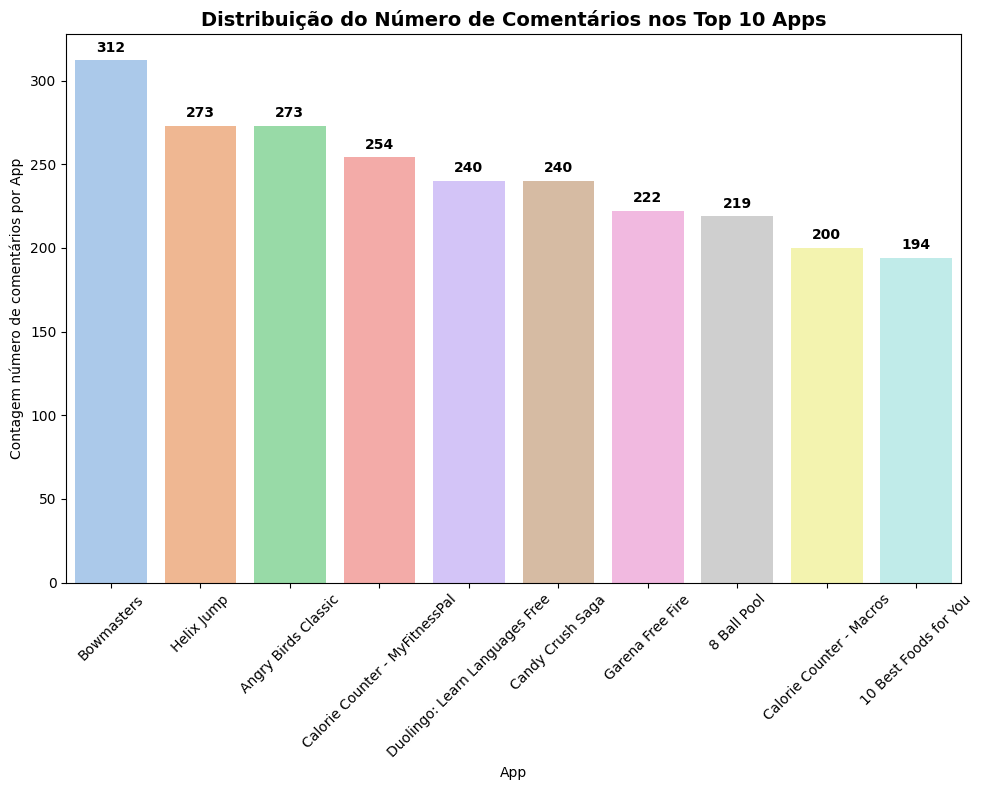

In [ ]:
top_10_apps = df['App'].value_counts().index[:10]

colors = sns.color_palette("pastel", n_colors=len(top_10_apps))

plt.figure(figsize=(10, 8))
ax = sns.countplot(
    x='App',
    data=df,
    order=top_10_apps,
    palette=colors,
    legend=False
)

plt.title('Distribuição do Número de Comentários nos Top 10 Apps', fontsize=14, fontweight='bold')
plt.ylabel('Contagem número de comentários por App')
plt.xlabel('App')
plt.xticks(rotation=45)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{int(height)}',
        xy=(p.get_x() + p.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

É evidente a heterogeneidade do número de reviews por app: destacam-se aplicações como "Bowmasters" (312 reviews), "Helix Jump" (273) e "Angry Birds Classic" (273). O gráfico de barras mostra ainda um número significativo de apps com comentários a somar numa faixa perto dos 200 a 250. Contudo, constatamos também diversas aplicações com apenas 1 review, como são os casos da "Google Slides, Caf – Mon Compte" e "Calculator – unit converter".

### 2.2.3. Sentiment

In [ ]:
print("---------Número de sentimentos ------\n")
print(df["Sentiment"].value_counts())

---------Número de sentimentos ------

Sentiment
Positive    23998
Negative     8271
Neutral      5158
Name: count, dtype: int64


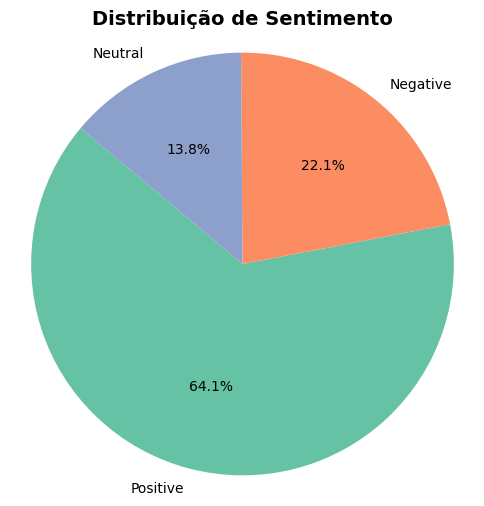

In [ ]:
sentiment_counts = df['Sentiment'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    colors=sns.color_palette('Set2'),
    autopct='%1.1f%%',
    startangle=140)

plt.title('Distribuição de Sentimento', fontsize=14, fontweight='bold')
plt.axis('equal')
plt.show()

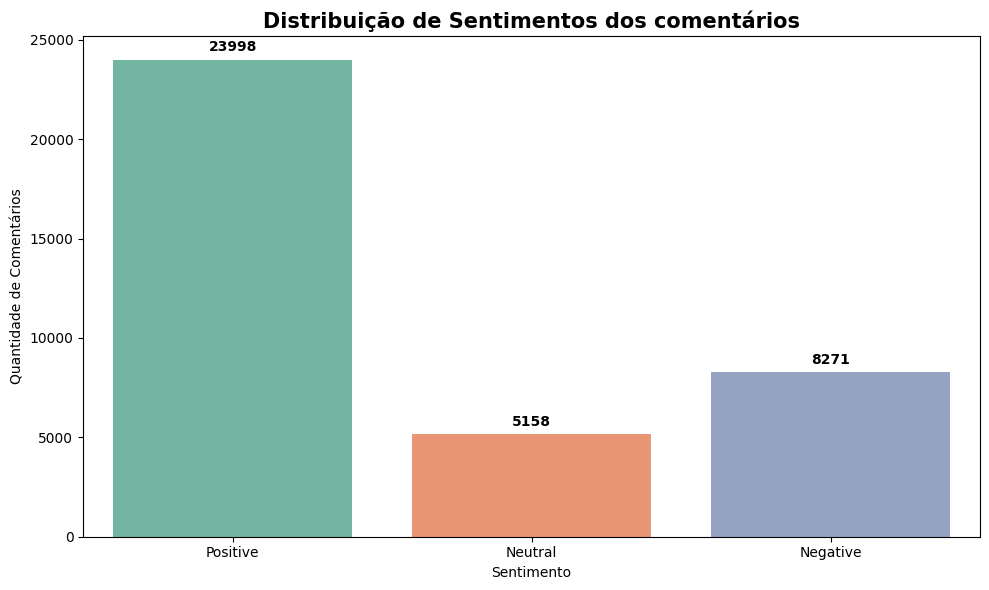

In [ ]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='Sentiment', hue='Sentiment', palette='Set2')

plt.title('Distribuição de Sentimentos dos comentários', fontsize=15, fontweight='bold')
plt.ylabel('Quantidade de Comentários')
plt.xlabel('Sentimento')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height)}',
                xy=(p.get_x() + p.get_width() / 2, height),
                xytext=(0, 4),
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

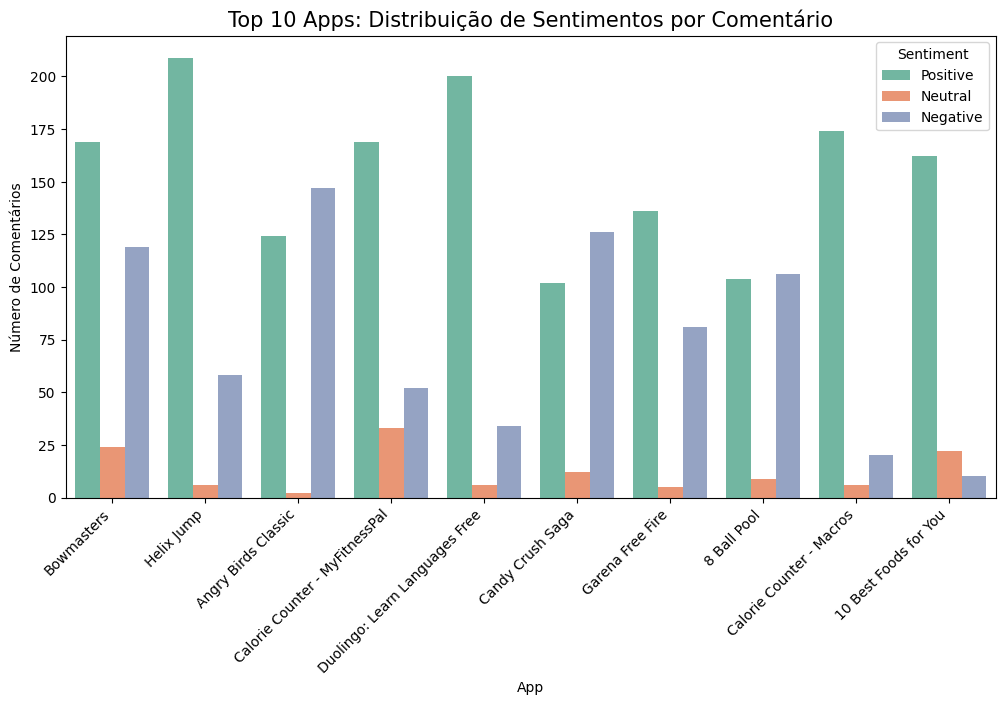

In [ ]:
plt.figure(figsize=(12, 6))

top_10_apps = df['App'].value_counts().head(10).index

sns.countplot(
    data=df,
    x='App',
    hue='Sentiment',
    order=top_10_apps,
    palette='Set2')

plt.title('Top 10 Apps: Distribuição de Sentimentos por App', fontsize=15)
plt.ylabel('Número de Comentários')
plt.xlabel('App')
plt.xticks(rotation=45, ha='right')

plt.show()

Ao estudar a divisão da coluna `Sentiment` pelas suas três categorias, é notório um acentuado desequilíbrio. Cerca de 64,1% dos comentários registamos estão associados a um sentimento positivo, num valor absoluto de 23998. Pelo contrário, o sentimento negativo é apontado a apenas 8271 registos, o que representa por mais de 22% do dataset. Temos ainda um pouco mais de 5000 reviews consideradas neutras, que mais tarde serão apagadas pois não oferecem informação relevante ao modelo, sendo responsáveis por 13,8% do df original. Outro dado importante de analisar é que do top 10 de aplicações com mais reviews, três contam com mais comentários negativos do que positivos, o que enfraquece a ideia hipotética de que o número de comentários e o tipo de sentimentos são dois pontos correlacionados. De acrescentar, ainda, que a décima app mais comentada ("10 Best Foods for you") soma mais neutros do que negativos, o que destoa do restante top 10.

### 2.2.4. Sentiment_Polarity

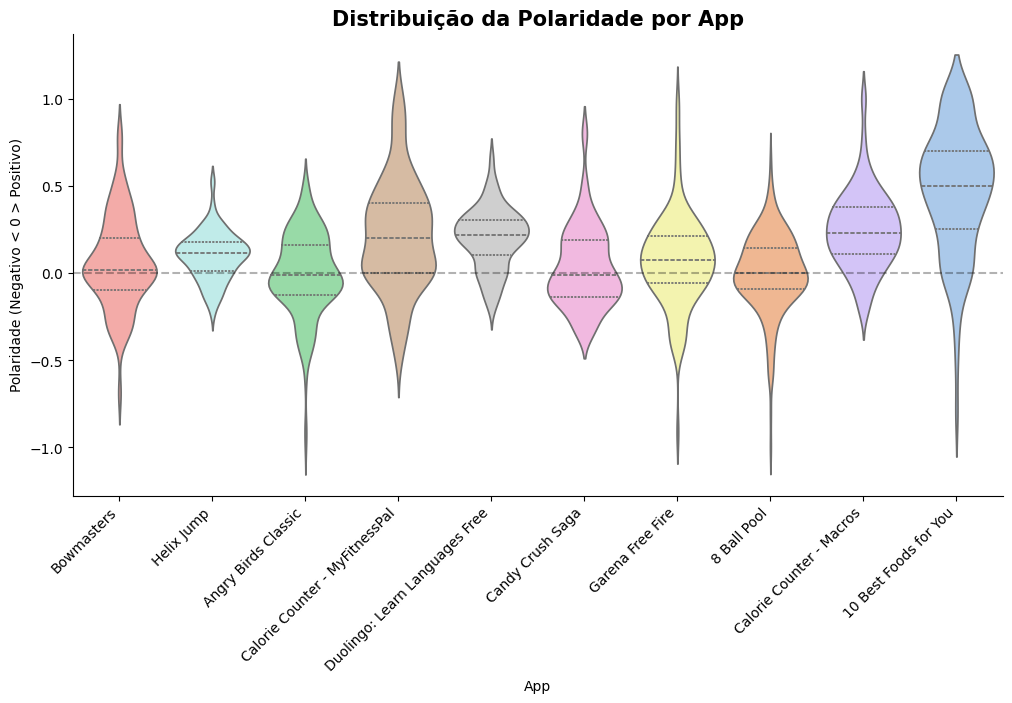

In [ ]:
top_10_names = df['App'].value_counts().nlargest(10).index
df_top = df[df['App'].isin(top_10_names)]

colors = sns.color_palette("pastel", n_colors=len(top_10_apps))

plt.figure(figsize=(12, 6))
sns.violinplot(data=df_top, x='App', y='Sentiment_Polarity', order=top_10_apps,
               palette=colors, hue='App', legend=False, inner="quart")

plt.axhline(0, color='black', linestyle='--', alpha=0.3)

plt.title('Distribuição da Polaridade por App', fontsize=15, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Polaridade (Negativo < 0 > Positivo)')
sns.despine()
plt.show()

A `Sentiment_Polarity` é, como descrito acima, uma coluna com valores decimais (float64) que representa uma escala de -1 a 1. Pensando num comentário exemplo, quanto mais perto o seu valor do -1, mais associado a um sentimento negativo e, seguindo a mesma lógica, mais positivo quando perto de 1. Um comentário com `Sentiment_Polarity` em torno de zero é classificado como neutro. Decidimos utilizar um gráfico de violino já que este não só nos permite avaliar a distribuição de polaridade de uma app, como possibilita uma fácil comparação entre apps. Podemos, ainda, entender que as aplicações com gráficos com caudas menos esticadas contam com opiniões mais homogéneas por parte dos utilizadores. As 3 aplicações com mais comentários negativos do que positivos são também as que contam com uma base mais larga no hemisfério inferior do gráfico. Ao mesmo tempo, aplicações como "Helix Jump", "Duolingo: Learn Languages Free" e "10 Best Foods for You", que apresentam uma grande vantagem de reviews positivas em relação a negativas, concentram-se quase exclusivamente na faixa entre 0 e 1.

### 2.2.5. Sentiment_Subjectivity

/tmp/ipykernel_22422/3480554158.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=sub_niveis, palette='Set2', order=sub_niveis.cat.categories)


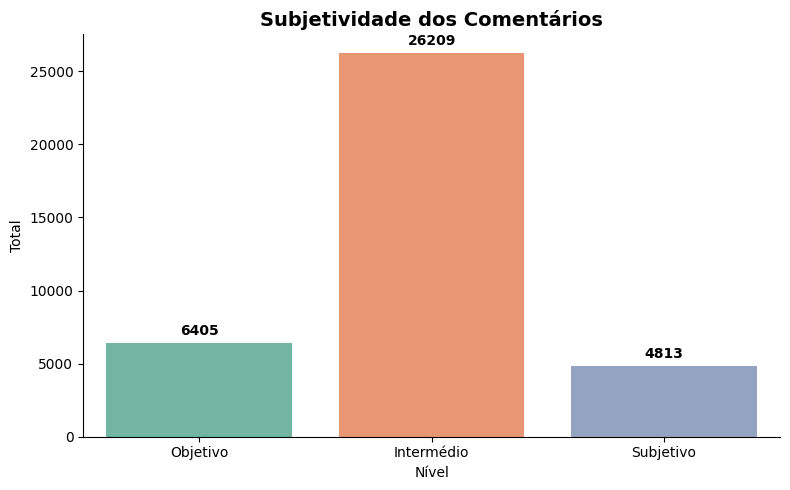

In [ ]:
sub_niveis = pd.cut(
    df['Sentiment_Subjectivity'],
    bins=[0, 0.25, 0.75, 1],
    labels=['Objetivo', 'Intermédio', 'Subjetivo'],
    include_lowest=True
)

plt.figure(figsize=(8, 5))
ax = sns.countplot(x=sub_niveis, palette='Set2', order=sub_niveis.cat.categories)

plt.title('Subjetividade dos Comentários', fontsize=14, fontweight='bold')
plt.ylabel('Total')
plt.xlabel('Nível')
plt.legend([], [], frameon=False)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{int(height)}',
        xy=(p.get_x() + p.get_width() / 2, height),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

sns.despine()
plt.tight_layout()
plt.show()

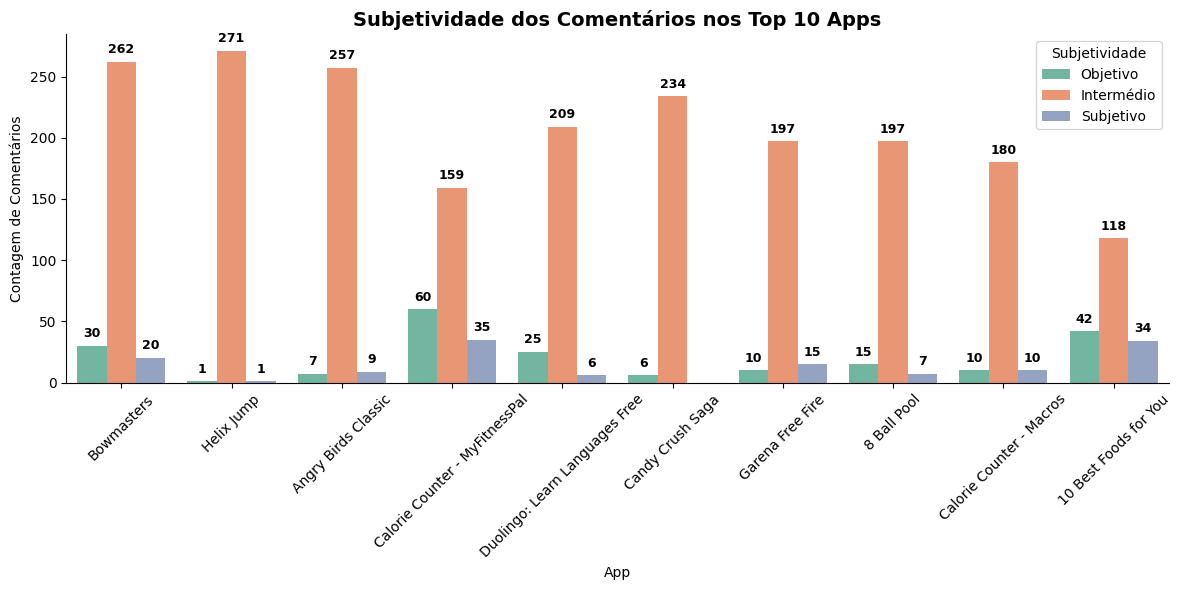

In [ ]:
top_10_apps = df['App'].value_counts().index[:10]
df_top = df[df['App'].isin(top_10_apps)].copy()

df_top['Subjetividade'] = pd.cut(
    df_top['Sentiment_Subjectivity'],
    bins=[0, 0.25, 0.75, 1],
    labels=['Objetivo', 'Intermédio', 'Subjetivo'],
    include_lowest=True
)

plt.figure(figsize=(12, 6))
ax = sns.countplot(
    x='App',
    hue='Subjetividade',
    data=df_top,
    order=top_10_apps,
    palette='Set2'
)

plt.title('Subjetividade dos Comentários nos Top 10 Apps', fontsize=14, fontweight='bold')
plt.ylabel('Contagem de Comentários')
plt.xlabel('App')
plt.xticks(rotation=45)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{int(height)}',
            xy=(p.get_x() + p.get_width() / 2, height),
            xytext=(0, 4),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=9,
            fontweight='bold'
        )

plt.legend(title='Subjetividade')
sns.despine()
plt.tight_layout()
plt.show()

A quinta coluna, `Sentiment_Subjetivity`, representa quantitativamente a subjetividade de cada review numa escala de 0 a 1. Dada a variabilidade dos dados, que dificultam a interpretação desta variável, decidimos que seria uma boa prática de análise estabelecer intervalos de subjetividade (bins). Assim, consideramos como objetivo se o valor se encontrar no range [0, 0.25], intermédio se for (0.25, 0.75] e subjetivo na faixa (0.75, 1]. Avaliando a distribuição destes três bins no dataset, verificamos que a grande maioria das reviews podem ser classificadas como subjetividade intermédia, ou seja, o texto do comentário não indica uma clara e evidente objetividade, nem é passível de dedução subjetiva. Os comentários que são considerados, com base nos nossos intervalos, como objetivos ou subjetivos compõem apenas aproximadamente 30% do csv, sendo distribuídos em 6405 objetivos e 4813 subjetivos. Analisando, em acréscimo, a divisão de intervalos de subjetividade no top 10 de apps mais referidas, podemos afirmar que todos contam com um espectro semelhante de subjetividade, com exceção de "Calorie Counter - MyFitnessPal" e "10 Best Foods for You", que somam mais comentários quer objetivos quer subjetivos em comparação com as restantes aplicações.

## **2.3. Análise da WorldCloud**

In [ ]:
# Unir todas as reviews numa única string separada por espaços
all_words = ' '.join(df['Translated_Review'])

# Mostrar número total de palavras e caracteres do corpus textual
print("Número de termos =", len(all_words.split()))
print("Número de caracteres =", len(all_words))

Número de termos = 686843
Número de caracteres = 4276354


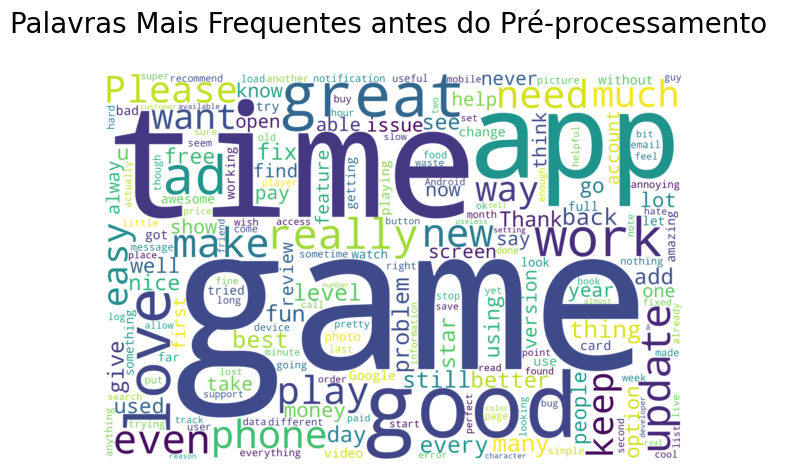

In [ ]:
wordcloud = WordCloud(
    width=3000,
    height=2000,
    background_color='white',
    colormap='viridis',
    collocations=False
).generate(all_words)

plt.figure(figsize=(15, 5))

plt.imshow(wordcloud, interpolation='bilinear')
plt.title('Palavras Mais Frequentes antes do Pré-processamento \n', fontsize=20)

plt.axis('off')
plt.show()

A visualização através da WordCloud destaca termos centrais como ***"game", "time", "app", "love", "good" e "great"***. A predominância de palavras de conotação positiva reforça as conclusões da análise de distribuição de sentimentos, enquanto termos como ***"update"*** ou ***"ad"*** sugerem os tópicos mais frequentemente abordados pelos utilizadores nas suas críticas negativas.

## **2.4. Contagem de Palavras Únicas**

In [ ]:
# Tokenizar o texto em palavras
palavras = word_tokenize(all_words)

# Criar conjunto de palavras únicas
unique_words = set(palavras)

# Contar número de palavras distintas
num_palavras_unicas = len(unique_words)

print("Número de palavras únicas:", num_palavras_unicas)

Número de palavras únicas: 30827


In [ ]:
# Voltar a contar o número de reviews por categoria de sentimento
print("--------- Número de sentimentos ---------")
print(df["Sentiment"].value_counts())

--------- Número de sentimentos ---------
Sentiment
Positive    23998
Negative     8271
Neutral      5158
Name: count, dtype: int64


#**3. Técnicas de Pré-processamento**

Após desenvolvida a análise exploratória, decidimos colocar em prática diversas técnicas de data cleaning e de pré-processamento. A análise revela-nos que não é crucial o tratamento de valores nulos (não existentes no dataset), assim como não é necessária a alteração de dtypes das features presentes. Avaliamos como importante somente a remoção de linhas duplicadas, que além de não acrescentarem informação relevante para os modelos, agravam o problema de desequilíbrio de classes na coluna target ('Sentiment'). Avançando, aplicamos um leque de técnicas de pré-processamento que prepararão os dados para modelação:

- Remoção comentários/reviews com sentimento neutro
- Conversão da coluna 'Translated_Review: conversão de dtype para str; conversão para minúsculas
- Tratamento de Chatwords
- Expansão de contrações de palavras
- Tratamento de Emoticons
- Tratamento de Emojis
- Remoção de pontuação
- Tratamento da negação
- Remoção de StopWords
- Lematização
- Tokenização
- Remoção de palavras não válidas

No final deste bloco analisamos uma nova WordCloud com a variável com texto lematizado, que possibilita a comparação com a WordCloud do dataset original.

In [ ]:
df_pre_process = df.copy()

## **3.1. Remoção dos Duplicados**

In [ ]:
df_pre_process = df_pre_process.drop_duplicates()

## **3.2. Remoção de comentários/reviews com sentimento neutro**


In [ ]:
df_pre_process = df_pre_process[df_pre_process['Sentiment'] != "Neutral"].reset_index(drop=True)
display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,"I like eat delicious food. That's I'm cooking food myself, case ""10 Best Foods"" helps lot, also ""Best Before (Shelf Life)"""
1,This help eating healthy exercise regular basis
2,Works great especially going grocery store
3,Best idea us
4,Best way
5,Amazing
6,good you.
7,"Useful information The amount spelling errors questions validity information shared. Once fixed, 5 stars given."
8,"Thank you! Great app!! Add arthritis, eyes, immunity, kidney/liver detox foods please. :)"
9,Greatest ever Completely awesome maintain health.... This must ppl there... Love it!!!


## **3.3. Conversões da coluna 'Translated_Review'**



### 3.3.1. Conversão do dtype para string

In [ ]:
pd.set_option("mode.copy_on_write", True)

df_pre_process['Translated_Review'] = df_pre_process['Translated_Review'].astype(str)

display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,"I like eat delicious food. That's I'm cooking food myself, case ""10 Best Foods"" helps lot, also ""Best Before (Shelf Life)"""
1,This help eating healthy exercise regular basis
2,Works great especially going grocery store
3,Best idea us
4,Best way
5,Amazing
6,good you.
7,"Useful information The amount spelling errors questions validity information shared. Once fixed, 5 stars given."
8,"Thank you! Great app!! Add arthritis, eyes, immunity, kidney/liver detox foods please. :)"
9,Greatest ever Completely awesome maintain health.... This must ppl there... Love it!!!


In [ ]:
# Unir todas as reviews numa única string
texto = ' '.join(df_pre_process['Translated_Review'])

# Separar palavras por espaços
palavras = texto.split()

# Criar conjunto de palavras únicas
unique_words = set(palavras)

# Contar número de palavras distintas
num_palavras_unicas = len(unique_words)

# Contar palavras distintas e totais
num_palavras_unicas = len(unique_words)
num_palavras = len(palavras)

print("Número de palavras únicas:", num_palavras_unicas)
print("Número total de palavras:", num_palavras)

Número de palavras únicas: 49640
Número total de palavras: 478545


### 3.3.2. Conversão para minúsculas

In [ ]:
df_pre_process["Translated_Review"] = df_pre_process["Translated_Review"].str.lower()
display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,"i like eat delicious food. that's i'm cooking food myself, case ""10 best foods"" helps lot, also ""best before (shelf life)"""
1,this help eating healthy exercise regular basis
2,works great especially going grocery store
3,best idea us
4,best way
5,amazing
6,good you.
7,"useful information the amount spelling errors questions validity information shared. once fixed, 5 stars given."
8,"thank you! great app!! add arthritis, eyes, immunity, kidney/liver detox foods please. :)"
9,greatest ever completely awesome maintain health.... this must ppl there... love it!!!


In [ ]:
# Unir todas as reviews numa única string
texto = ' '.join(df_pre_process['Translated_Review'])

# Separar palavras por espaços
palavras = texto.split()

# Criar conjunto de palavras únicas
unique_words = set(palavras)

# Contar número de palavras distintas
num_palavras_unicas = len(unique_words)

# Contar palavras distintas e totais
num_palavras_unicas = len(unique_words)
num_palavras = len(palavras)

print("Número de palavras únicas:", num_palavras_unicas)
print("Número total de palavras:", num_palavras)

Número de palavras únicas: 42367
Número total de palavras: 478545


## **3.4. Expansão de Chatwords**

In [ ]:
chatwords = {
    "afaik": "as far as i know",
    "afk": "away from keyboard",
    "asap": "as soon as possible",
    "lol": "laugh out loud",
    "btw": "by the way",
    "brb": "be right back",
    "omg": "oh my god",
    "idk": "i don't know",
    "fyi": "for your information",
    "ity": "take your time",
    "thx": "thanks",
    "spk": "speak"
}

def expand_chatwords(text):
    words = word_tokenize(text)
    expanded_words = [
        chatwords[word] if word in chatwords else word
        for word in words
    ]
    return ' '.join(expanded_words)

df_pre_process["Translated_Review"] = df_pre_process["Translated_Review"].apply(expand_chatwords)

display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,"i like eat delicious food . that 's i 'm cooking food myself , case `` 10 best foods '' helps lot , also `` best before ( shelf life ) ''"
1,this help eating healthy exercise regular basis
2,works great especially going grocery store
3,best idea us
4,best way
5,amazing
6,good you .
7,"useful information the amount spelling errors questions validity information shared . once fixed , 5 stars given ."
8,"thank you ! great app ! ! add arthritis , eyes , immunity , kidney/liver detox foods please . : )"
9,greatest ever completely awesome maintain health .... this must ppl there ... love it ! ! !


In [ ]:
# Unir todas as reviews numa única string
texto = ' '.join(df_pre_process['Translated_Review'])

# Separar palavras por espaços
palavras = texto.split()

# Criar conjunto de palavras únicas
unique_words = set(palavras)

# Contar número de palavras distintas
num_palavras_unicas = len(unique_words)

# Contar palavras distintas e totais
num_palavras_unicas = len(unique_words)
num_palavras = len(palavras)

print("Número de palavras únicas:", num_palavras_unicas)
print("Número total de palavras:", num_palavras)

Número de palavras únicas: 22883
Número total de palavras: 580603


## **3.5. Remover elementos HTML**

In [ ]:
df_pre_process['Translated_Review'] = df_pre_process['Translated_Review'].apply(unescape)
df_pre_process['Translated_Review'] = df_pre_process['Translated_Review'].str.replace(r'<.*?>', '', regex=True)

display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,"i like eat delicious food . that 's i 'm cooking food myself , case `` 10 best foods '' helps lot , also `` best before ( shelf life ) ''"
1,this help eating healthy exercise regular basis
2,works great especially going grocery store
3,best idea us
4,best way
5,amazing
6,good you .
7,"useful information the amount spelling errors questions validity information shared . once fixed , 5 stars given ."
8,"thank you ! great app ! ! add arthritis , eyes , immunity , kidney/liver detox foods please . : )"
9,greatest ever completely awesome maintain health .... this must ppl there ... love it ! ! !


In [ ]:
# Unir todas as reviews numa única string
texto = ' '.join(df_pre_process['Translated_Review'])

# Separar palavras por espaços
palavras = texto.split()

# Criar conjunto de palavras únicas
unique_words = set(palavras)

# Contar número de palavras distintas
num_palavras_unicas = len(unique_words)

# Contar palavras distintas e totais
num_palavras_unicas = len(unique_words)
num_palavras = len(palavras)

print("Número de palavras únicas:", num_palavras_unicas)
print("Número total de palavras:", num_palavras)

Número de palavras únicas: 22882
Número total de palavras: 580591


## **3.6. Remover URLs dos comentários**

In [ ]:
df_pre_process['Translated_Review'] = df_pre_process['Translated_Review'].str.replace(r'http\S+|www\S+|https\S+', '', regex=True)

display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,"i like eat delicious food . that 's i 'm cooking food myself , case `` 10 best foods '' helps lot , also `` best before ( shelf life ) ''"
1,this help eating healthy exercise regular basis
2,works great especially going grocery store
3,best idea us
4,best way
5,amazing
6,good you .
7,"useful information the amount spelling errors questions validity information shared . once fixed , 5 stars given ."
8,"thank you ! great app ! ! add arthritis , eyes , immunity , kidney/liver detox foods please . : )"
9,greatest ever completely awesome maintain health .... this must ppl there ... love it ! ! !


In [ ]:
# Unir todas as reviews numa única string
texto = ' '.join(df_pre_process['Translated_Review'])

# Separar palavras por espaços
palavras = texto.split()

# Criar conjunto de palavras únicas
unique_words = set(palavras)

# Contar número de palavras distintas
num_palavras_unicas = len(unique_words)

# Contar palavras distintas e totais
num_palavras_unicas = len(unique_words)
num_palavras = len(palavras)

print("Número de palavras únicas:", num_palavras_unicas)
print("Número total de palavras:", num_palavras)

Número de palavras únicas: 22878
Número total de palavras: 580588


## **3.7. Expanção de contrações de palavras**

In [ ]:
df_pre_process["Translated_Review"] = df_pre_process["Translated_Review"].apply(contractions.fix)

display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,"i like eat delicious food . that 's i 'm cooking food myself , case `` 10 best foods '' helps lot , also `` best before ( shelf life ) ''"
1,this help eating healthy exercise regular basis
2,works great especially going grocery store
3,best idea us
4,best way
5,amazing
6,good you .
7,"useful information the amount spelling errors questions validity information shared . once fixed , 5 stars given ."
8,"thank you ! great app ! ! add arthritis , eyes , immunity , kidney/liver detox foods please . : )"
9,greatest ever completely awesome maintain health .... this must people there ... love it ! ! !


In [ ]:
# Unir todas as reviews numa única string
texto = ' '.join(df_pre_process['Translated_Review'])

# Separar palavras por espaços
palavras = texto.split()

# Criar conjunto de palavras únicas
unique_words = set(palavras)

# Contar número de palavras distintas
num_palavras_unicas = len(unique_words)

# Contar palavras distintas e totais
num_palavras_unicas = len(unique_words)
num_palavras = len(palavras)

print("Número de palavras únicas:", num_palavras_unicas)
print("Número total de palavras:", num_palavras)

Número de palavras únicas: 22801
Número total de palavras: 582053


## **3.8. Expansão de Emoticons**

In [ ]:
emoticons_dict = {
    ":-)": "happy face",
    ":)": "happy face",
    ":-(": "sad face",
    ":(": "sad face",
    ":-d": "laughing face",
    ":d": "laughing face",
    ";)": "winking face",
    ":-/": "confused face",
    ":/": "confused face"
}

emoticons_sorted = sorted(emoticons_dict.keys(), key=len, reverse=True)

for emoticon in emoticons_sorted:
    df_pre_process["Translated_Review"] = df_pre_process["Translated_Review"].str.replace(
        emoticon, emoticons_dict[emoticon], regex=False
    )

display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,"i like eat delicious food . that 's i 'm cooking food myself , case `` 10 best foods '' helps lot , also `` best before ( shelf life ) ''"
1,this help eating healthy exercise regular basis
2,works great especially going grocery store
3,best idea us
4,best way
5,amazing
6,good you .
7,"useful information the amount spelling errors questions validity information shared . once fixed , 5 stars given ."
8,"thank you ! great app ! ! add arthritis , eyes , immunity , kidney/liver detox foods please . : )"
9,greatest ever completely awesome maintain health .... this must people there ... love it ! ! !


In [ ]:
# Unir todas as reviews numa única string
texto = ' '.join(df_pre_process['Translated_Review'])

# Separar palavras por espaços
palavras = texto.split()

# Criar conjunto de palavras únicas
unique_words = set(palavras)

# Contar número de palavras distintas
num_palavras_unicas = len(unique_words)

# Contar palavras distintas e totais
num_palavras_unicas = len(unique_words)
num_palavras = len(palavras)

print("Número de palavras únicas:", num_palavras_unicas)
print("Número total de palavras:", num_palavras)

Número de palavras únicas: 22801
Número total de palavras: 582053


## **3.9. Conversão de Emojis em Texto**

In [ ]:
df_pre_process["Translated_Review"] = df_pre_process["Translated_Review"].apply(emoji.demojize)

display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,"i like eat delicious food . that 's i 'm cooking food myself , case `` 10 best foods '' helps lot , also `` best before ( shelf life ) ''"
1,this help eating healthy exercise regular basis
2,works great especially going grocery store
3,best idea us
4,best way
5,amazing
6,good you .
7,"useful information the amount spelling errors questions validity information shared . once fixed , 5 stars given ."
8,"thank you ! great app ! ! add arthritis , eyes , immunity , kidney/liver detox foods please . : )"
9,greatest ever completely awesome maintain health .... this must people there ... love it ! ! !


In [ ]:
# Unir todas as reviews numa única string
texto = ' '.join(df_pre_process['Translated_Review'])

# Separar palavras por espaços
palavras = texto.split()

# Criar conjunto de palavras únicas
unique_words = set(palavras)

# Contar número de palavras distintas
num_palavras_unicas = len(unique_words)

# Contar palavras distintas e totais
num_palavras_unicas = len(unique_words)
num_palavras = len(palavras)

print("Número de palavras únicas:", num_palavras_unicas)
print("Número total de palavras:", num_palavras)

Número de palavras únicas: 22801
Número total de palavras: 582053


## **3.10. Remoção da pontuação**

In [ ]:
df_pre_process["Translated_Review"] = df_pre_process["Translated_Review"].str.replace(r'[^\w\s]+', '', regex=True)
display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,i like eat delicious food that s i m cooking food myself case 10 best foods helps lot also best before shelf life
1,this help eating healthy exercise regular basis
2,works great especially going grocery store
3,best idea us
4,best way
5,amazing
6,good you
7,useful information the amount spelling errors questions validity information shared once fixed 5 stars given
8,thank you great app add arthritis eyes immunity kidneyliver detox foods please
9,greatest ever completely awesome maintain health this must people there love it


In [ ]:
# Unir todas as reviews numa única string
texto = ' '.join(df_pre_process['Translated_Review'])

# Separar palavras por espaços
palavras = texto.split()

# Criar conjunto de palavras únicas
unique_words = set(palavras)

# Contar número de palavras distintas
num_palavras_unicas = len(unique_words)

# Contar palavras distintas e totais
num_palavras_unicas = len(unique_words)
num_palavras = len(palavras)

print("Número de palavras únicas:", num_palavras_unicas)
print("Número total de palavras:", num_palavras)

Número de palavras únicas: 21688
Número total de palavras: 490116


## **3.11. Tratamento da negação**

In [ ]:
negations = ['not', 'no', 'cannot']

def get_antonym(word):
    for syn in wordnet.synsets(word):
        for lemma in syn.lemmas():
            if lemma.antonyms():
                return lemma.antonyms()[0].name()
    return None

def replace_negation_with_antonym(text):
    tokens = word_tokenize(str(text))
    new_tokens = []
    i = 0
    while i < len(tokens):
        token = tokens[i]
        lower = token.lower()
        if lower in negations and i + 1 < len(tokens):
            next_word = tokens[i + 1]
            antonym = get_antonym(next_word)
            if antonym:
                new_tokens.append(antonym)
                i += 2
                continue
        new_tokens.append(token)
        i += 1
    return ' '.join(new_tokens)

df_pre_process["Translated_Review"] = df_pre_process["Translated_Review"].apply(replace_negation_with_antonym)

display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,i like eat delicious food that s i m cooking food myself case 10 best foods helps lot also best before shelf life
1,this help eating healthy exercise regular basis
2,works great especially going grocery store
3,best idea us
4,best way
5,amazing
6,good you
7,useful information the amount spelling errors questions validity information shared once fixed 5 stars given
8,thank you great app add arthritis eyes immunity kidneyliver detox foods please
9,greatest ever completely awesome maintain health this must people there love it


In [ ]:
# Unir todas as reviews numa única string
texto = ' '.join(df_pre_process['Translated_Review'])

# Separar palavras por espaços
palavras = texto.split()

# Criar conjunto de palavras únicas
unique_words = set(palavras)

# Contar número de palavras distintas
num_palavras_unicas = len(unique_words)

# Contar palavras distintas e totais
num_palavras_unicas = len(unique_words)
num_palavras = len(palavras)

print("Número de palavras únicas:", num_palavras_unicas)
print("Número total de palavras:", num_palavras)

Número de palavras únicas: 21803
Número total de palavras: 488512


## **3.12. Remoção de StopWords**

In [ ]:
stop_words = stopwords.words('english')

review_without_stopwords = []

for text in df_pre_process["Translated_Review"]:
    words_t = word_tokenize(text)

    filtered_words = [word for word in words_t if word not in stop_words]

    filtered_text = ' '.join(filtered_words)
    review_without_stopwords.append(filtered_text)

df_pre_process["Translated_Review"] = review_without_stopwords

display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,like eat delicious food cooking food case 10 best foods helps lot also best shelf life
1,help eating healthy exercise regular basis
2,works great especially going grocery store
3,best idea us
4,best way
5,amazing
6,good
7,useful information amount spelling errors questions validity information shared fixed 5 stars given
8,thank great app add arthritis eyes immunity kidneyliver detox foods please
9,greatest ever completely awesome maintain health must people love


In [ ]:
# Unir todas as reviews numa única string
texto = ' '.join(df_pre_process['Translated_Review'])

# Separar palavras por espaços
palavras = texto.split()

# Criar conjunto de palavras únicas
unique_words = set(palavras)

# Contar número de palavras distintas
num_palavras_unicas = len(unique_words)

# Contar palavras distintas e totais
num_palavras_unicas = len(unique_words)
num_palavras = len(palavras)

print("Número de palavras únicas:", num_palavras_unicas)
print("Número total de palavras:", num_palavras)

Número de palavras únicas: 21667
Número total de palavras: 396362


## **3.13. Lematização**

In [ ]:
lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    tokens = word_tokenize(str(text))
    lemmatized_words = [lemmatizer.lemmatize(word) for word in tokens]
    return ' '.join(lemmatized_words)

df_pre_process["Translated_Review"] = df_pre_process["Translated_Review"].apply(lemmatize_text)

display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,like eat delicious food cooking food case 10 best food help lot also best shelf life
1,help eating healthy exercise regular basis
2,work great especially going grocery store
3,best idea u
4,best way
5,amazing
6,good
7,useful information amount spelling error question validity information shared fixed 5 star given
8,thank great app add arthritis eye immunity kidneyliver detox food please
9,greatest ever completely awesome maintain health must people love


In [ ]:
# Unir todas as reviews numa única string
texto = ' '.join(df_pre_process['Translated_Review'])

# Separar palavras por espaços
palavras = texto.split()

# Criar conjunto de palavras únicas
unique_words = set(palavras)

# Contar número de palavras distintas
num_palavras_unicas = len(unique_words)

# Contar palavras distintas e totais
num_palavras_unicas = len(unique_words)
num_palavras = len(palavras)

print("Número de palavras únicas:", num_palavras_unicas)
print("Número total de palavras:", num_palavras)

Número de palavras únicas: 19493
Número total de palavras: 396362


## **3.14. Tokenização**


In [ ]:
df_pre_process["Tokenization"] = df_pre_process["Translated_Review"].apply(word_tokenize)


display(df_pre_process[['Tokenization']].head(10))

,Tokenization
0,"[like, eat, delicious, food, cooking, food, case, 10, best, food, help, lot, also, best, shelf, life]"
1,"[help, eating, healthy, exercise, regular, basis]"
2,"[work, great, especially, going, grocery, store]"
3,"[best, idea, u]"
4,"[best, way]"
5,[amazing]
6,[good]
7,"[useful, information, amount, spelling, error, question, validity, information, shared, fixed, 5, star, given]"
8,"[thank, great, app, add, arthritis, eye, immunity, kidneyliver, detox, food, please]"
9,"[greatest, ever, completely, awesome, maintain, health, must, people, love]"


##**3.15. Remoção de palavras não válidas**

In [ ]:
english_words = set(nltk_words.words())

filtered_texts = []

for tokens in df_pre_process["Tokenization"]:
    valid_words = [
        w for w in tokens
        if w.isalpha()
        and len(w) > 1
        and w.lower() in english_words
    ]

    filtered_texts.append(' '.join(valid_words))

df_pre_process["Translated_Review"] = filtered_texts
display(df_pre_process[['Translated_Review']].head(10))

,Translated_Review
0,like eat delicious food cooking food case best food help lot also best shelf life
1,help eating healthy exercise regular basis
2,work great especially going grocery store
3,best idea
4,best way
5,amazing
6,good
7,useful information amount spelling error question validity information fixed star given
8,thank great add arthritis eye immunity food please
9,ever completely awesome maintain health must people love


##**3.16. Construção do conjunto final para modelação**

In [ ]:
# Criar DataFrame final e renomear colunas para nomenclatura mais simples
df_final = df_pre_process[["Translated_Review", "Sentiment"]].rename(
    columns={
        "Translated_Review": "text",
        "Sentiment": "sentiment"
    }
)

In [ ]:
df_final

,text,sentiment
0,like eat delicious food cooking food case best food help lot also best shelf life,Positive
1,help eating healthy exercise regular basis,Positive
2,work great especially going grocery store,Positive
3,best idea,Positive
4,best way,Positive
...,...,...
25331,ad older many agent little owner posted detail report ad option even wrong information also posted,Positive
25332,photo posted portal load fit purpose sure storage technology use experience photo load issue similar application technical team need test rigorously improve production environment,Positive
25333,dumb post property rent give option work waste time space phone,Negative
25334,property business got link happy performance still guy need raise bar guy cheer,Positive


##**3.17. WordCloud final**

In [ ]:
# Unir todas as reviews lematizadas numa única string
all_words = ' '.join(df_final['text'])

# Mostrar número total de palavras e caracteres do corpus textual
print("Número de termos =", len(all_words.split()))
print("Número de caracteres =", len(all_words))

Número de termos = 336623
Número de caracteres = 2146815


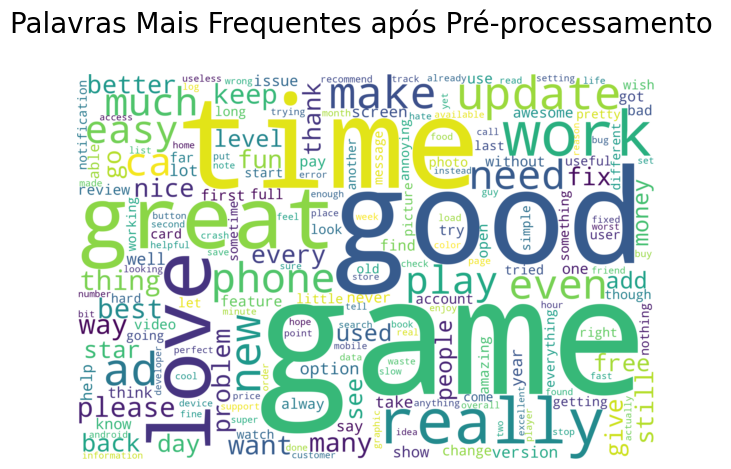

In [ ]:
wordcloud = WordCloud(
    width=3000,
    height=2000,
    background_color='white',
    colormap='viridis',
    collocations=False
).generate(all_words)

plt.figure(figsize=(20, 5))
plt.imshow(wordcloud, interpolation='bilinear')

plt.axis('off')

plt.title('Palavras Mais Frequentes após Pré-processamento \n', fontsize=20)

plt.show()

#**4. Balanceamento de classes - Oversampling**

In [ ]:
df_majority = df_final[df_final.sentiment == "Positive"]
df_minority = df_final[df_final.sentiment == "Negative"]

# Oversampling da classe minoritária
df_minority_upsampled = resample(
    df_minority,
    replace=True,
    n_samples=len(df_majority),
    random_state=123
)

# Criar DataFrame balanceado
df_balanced_oversampling = pd.concat([df_majority, df_minority_upsampled])

# Verificar distribuição final
print("Distribuição após oversampling:")
print(df_balanced_oversampling['sentiment'].value_counts())

Distribuição após oversampling:
sentiment
Positive    19015
Negative    19015
Name: count, dtype: int64


In [ ]:
# Definir como conjunto final o DataFrame obtido após undersampling,
df_final = df_balanced_oversampling

In [ ]:
# Visualizar o DataFrame final após a selecção do conjunto balanceado
df_final

,text,sentiment
0,like eat delicious food cooking food case best food help lot also best shelf life,Positive
1,help eating healthy exercise regular basis,Positive
2,work great especially going grocery store,Positive
3,best idea,Positive
4,best way,Positive
...,...,...
13254,piece junk got company saying free would keep password older version big lying lost password hope bring back keep word would afraid never know could happen say thing another thing,Negative
9297,work ca login difficult way get support,Negative
16920,recent post one hour day behind current time getting annoying stupid old post someone recently recent post option,Negative
13999,convenient way seek treatment cold flu thorough definitely future,Negative


Tal como veríficamos no ponto 2.2.3., o nosso conjunto de dados apresenta um grande desiquilíbrio, onde existe mais comentários da classe positiva (23998) do que negativa (8271). Para equilibrar as classes, optámos por utilizar a técnica de oversampling para a classe minoritária. Tomámos esta decisão para não distorcer os dados e evitar problemas de overfitting. Se tivéssemos optado pelo undersampling, acabaríamos por perder uma grande quantidade de dados da classe positiva, removendo informação potencial para a aprendizagem do modelo.

#**5. Representação Vectorial - TF-IDF**

In [ ]:
# 7.1. Definir variáveis de texto (X) e alvo (y)
X = df_final["text"]
y = df_final["sentiment"]

# 7.2. Dividir em treino (70%) e teste (30%) NO TEXTO BRUTO
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=0,
    stratify=y,
    shuffle=True
)

print("Treino:", X_train.shape[0], "documentos")
print("Teste :", X_test.shape[0], "documentos")

# 7.3. Criar vectorizador TF-IDF
tfidf_vectorizer = TfidfVectorizer()

# 7.4. Ajustar TF-IDF apenas no treino (fit + transform)  → SEM data leakage
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# 7.5. Aplicar a mesma transformação ao teste (só transform)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# 7.6. Informação básica sobre as matrizes
print("\nX_train_tfidf:", X_train_tfidf.shape)
print("X_test_tfidf :", X_test_tfidf.shape)

# 7.7. Obter lista de termos do vocabulário (aprendido só no treino)
termos = tfidf_vectorizer.get_feature_names_out()
print("\nNúmero total de termos no vocabulário:", len(termos))

# 7.8. (Opcional) inspecionar a primeira linha do treino em formato denso
X_train_dense = X_train_tfidf.toarray()
df_tfidf_train = pd.DataFrame(X_train_dense, columns=termos, index=y_train.index)

print("\nPrimeira linha (apenas termos com TF-IDF > 0):")
linha_0 = df_tfidf_train.iloc[0]
display(linha_0[linha_0 != 0])


Treino: 26621 documentos
Teste : 11409 documentos

X_train_tfidf: (26621, 8289)
X_test_tfidf : (11409, 8289)

Número total de termos no vocabulário: 8289

Primeira linha (apenas termos com TF-IDF > 0):


,13725
acceptable,0.195430
alarm,0.158413
another,0.117103
back,0.097144
bad,0.100419
best,0.101829
clock,0.161703
come,0.116018
contact,0.137865
customer,0.253224


#**6. Seleção de melhores features**

In [ ]:
# Selecção das 10000 melhores features apenas no conjunto de treino
# O selector.fit_transform usa apenas X_train_tfidf e y_train para escolher as 1000 melhores features.
# O X_test_tfidf é apenas transformado, sem influenciar a seleção
# O teste não intervém na definição das features, o que é exatamente o que se pretende.

# 8.1. Criar seletor de 1000 features com teste Qui-Quadrado
selector = SelectKBest(chi2, k=1000)

# 8.2. Ajustar seletor apenas no treino e transformar treino
X_train_sel = selector.fit_transform(X_train_tfidf, y_train)

# 8.3. Transformar o conjunto de teste com as mesmas features
X_test_sel = selector.transform(X_test_tfidf)

# 8.4. Obter índices e nomes das melhores features
selected_idx = selector.get_support(indices=True)
bestfeatures = [termos[i] for i in selected_idx]

print("Número de melhores features:", len(bestfeatures))

# 8.5. (Opcional) DataFrame das features seleccionadas para o treino
df_train_sel = pd.DataFrame(
    X_train_sel.toarray(),
    columns=bestfeatures,
    index=y_train.index
)
display(df_train_sel.head())

# 8.6. (Opcional) ver termos não nulos na primeira linha
linha_0_sel = df_train_sel.iloc[0]
print("\nPrimeira linha (features seleccionadas com TF-IDF > 0):")
display(linha_0_sel[linha_0_sel != 0])

Número de melhores features: 1000


,aa,ability,able,abolish,absolutely,absurd,accepted,access,account,accounting,accurate,achieve,acrobat,actively,ad,add,addicted,administration,adorable,advanced,advert,advertisement,advertising,affordable,afraid,agile,agree,ai,aka,alarm,alert,allow,allowance,alma,almost,already,amaze,amazed,amazing,amazingly,amount,analysis,analytics,anatomy,ancient,angry,anime,annoying,another,anything,anyway,appalling,apparent,appealing,applied,appropriate,approximate,apt,arbitrary,artist,as,aside,assign,assume,ate,atrocious,attachment,attractive,audible,authentication,authorized,automatic,availability,available,average,avoid,awesome,awful,awkward,back,bad,badge,badly,ball,banger,bank,barely,base,basic,basketball,bat,bathroom,beating,beautiful,beautifully,become,becomes,behind,best,better,billion,bird,black,blame,blatant,bloat,block,blocked,blocking,blood,bloody,blueprint,bonus,bookmark,boost,bore,boredom,boring,bother,bought,bounty,breeze,bridge,bright,brightness,brilliant,broken,bubble,buffer,bug,buggy,builder,bumpy,bundle,busy,butterfly,buy,ca,cable,cache,calculate,calculating,call,calorie,campus,canada,candy,care,carfax,carry,cart,casual,category,cause,censorship,charm,cheap,cheat,chime,chip,chrome,citation,clean,cleaner,clipped,clone,close,closed,clothes,clumsy,coin,cold,colorlessness,combine,comfortable,comic,comment,common,community,company,compatible,completely,complicated,concentration,confident,configuration,confine,confirming,confused,congratulation,connect,connection,conserve,constant,constantly,construct,consume,continuity,convenience,convenient,convert,cooking,cool,coop,corner,corrupt,costly,could,country,county,cow,crap,crash,crazy,creation,creative,crew,crush,cue,currency,customer,cut,cute,cutting,cycle,damn,dangerous,data,dating,dead,deal,death,defend,definitely,delay,delete,delicious,delta,dental,dependable,designed,despite,detailed,diabetes,diabetic,die,diet,difficult,dirty,disable,disabled,disappointed,disappointing,disappointment,disapprove,disconnect,disconnected,disgusting,dissatisfied,distance,disturbing,diverge,doc,doctor,document,domestic,donation,donkey,downhill,downside,dozen,dreadful,driving,drop,due,dull,dumb,duper,dying,easiest,easily,east,easy,edition,editor,educational,effect,effective,efficient,either,el,else,enable,end,endless,energy,engaging,enjoy,enjoyable,enterprise,entertaining,erase,error,estate,eternity,even,event,eventually,ever,every,everywhere,evil,exaggerating,excellent,excessive,excuse,exercise,expedient,expense,expensive,explanatory,extract,extremely,fabulous,facial,fail,failure,fair,fake,falling,false,familiar,family,fantastic,fantasy,far,farther,fast,favorite,feature,female,figured,file,filling,film,find,finding,first,fish,fit,fix,flat,floor,flower,fluid,food,football,force,forced,forecast,foreground,forever,format,formerly,found,free,freeze,freezing,frequency,fresh,friend,friendly,froze,frustrate,fuel,full,fun,funny,galaxy,gallery,galore,game,garbage,gas,gave,gear,gem,gender,get,getting,giving,glad,glucose,go,gold,golfer,gone,good,gorgeous,grandma,grant,graph,graphic,great,greatly,greedy,green,grind,grocery,guarantee,guide,gun,gym,habit,half,hall,handled,handy,hanging,happen,happening,happier,happily,happy,hard,harder,hardly,hate,headphone,healthy,hear,heat,heavy,heck,hell,hello,help,helpful,herpes,hidden,highly,hilarious,hit,hog,homework,horrible,horribly,hostile,hot,hour,however,huge,hurt,husband,idea,ideal,idiot,idiotic,idle,ill,illegal,imagination,important,impossible,impressive,improve,inaccurate,included,inconvenient,incredible,informative,innumerable,insane,install,instead,instructional,intake,integration,intense,intentionally,interactive,interesting,irritating,issue,jam,jewel,job,joke,jump,keep,keeping,kept,keto,keyboard,kicking,killer,kindle,knowing,knowledge,kudos,lag,lagging,lame,last,lately,latest,laugh,lay,leaf,learn,learned,learning,least,leave,legendary,less,let,letdown,level,lie,light,linked,literally,little,live,living,load,loading,location,locked,locking,log,logged,logging,l


Primeira linha (features seleccionadas com TF-IDF > 0):


,13725
alarm,0.158413
another,0.117103
back,0.097144
bad,0.100419
best,0.101829
customer,0.253224
data,0.122919
excuse,0.196552
fix,0.094661
giving,0.145249


#**7. Treino e Avaliação dos Modelos de Classificação**

In [ ]:
np.random.seed(0)

# 2. Dicionário com os teus modelos originais
models = {
    "SVC": SVC(),
    "RandomForest": RandomForestClassifier(),
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "GaussianNB": GaussianNB(),
    "DecisionTree": DecisionTreeClassifier(),
    "AdaBoost": AdaBoostClassifier(),
    "GradientBoosting": GradientBoostingClassifier(),
    "KNN": KNeighborsClassifier(),
    "LightGBM": LGBMClassifier()
}

y_preds = {}
results = []

for name, model in models.items():
    print(f"A treinar {name} com GridSearchCV (CV=10)...")

    # Apenas o GaussianNB precisa do .toarray(). Todos os outros correm 10x mais rápido com a matriz esparsa original!
    if name == "GaussianNB":
        X_tr_input = X_train_sel.toarray()
        X_te_input = X_test_sel.toarray()
    else:
        X_tr_input = X_train_sel
        X_te_input = X_test_sel

    # Criamos o GridSearch (retirámos o n_jobs=-1 para evitar conflito de memória e processamento)
    grid_search = GridSearchCV(estimator=model, param_grid={}, cv=10, scoring='f1_weighted')

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        grid_search.fit(X_tr_input, y_train)

    # Update the model in the dictionary with the best fitted estimator
    models[name] = grid_search.best_estimator_

    # Previsão
    y_pred = models[name].predict(X_te_input)
    y_preds[name] = y_pred

    results.append({
        "Model": name,
        "Acc": accuracy_score(y_test, y_pred),
        "Prec": precision_score(y_test, y_pred, average='weighted', zero_division=0),
        "Rec": recall_score(y_test, y_pred, average='weighted'),
        "F1": f1_score(y_test, y_pred, average='weighted')
    })

df_models_results = pd.DataFrame(results).sort_values(by="F1", ascending=False)
print(df_models_results)

A treinar SVC com GridSearchCV (CV=10)...
A treinar RandomForest com GridSearchCV (CV=10)...
A treinar LogisticRegression com GridSearchCV (CV=10)...
A treinar GaussianNB com GridSearchCV (CV=10)...
A treinar DecisionTree com GridSearchCV (CV=10)...
A treinar AdaBoost com GridSearchCV (CV=10)...
A treinar GradientBoosting com GridSearchCV (CV=10)...
A treinar KNN com GridSearchCV (CV=10)...
A treinar LightGBM com GridSearchCV (CV=10)...
[LightGBM] [Info] Number of positive: 11979, number of negative: 11979
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.207831 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 37433
[LightGBM] [Info] Number of data points in the train set: 23958, number of used features: 650
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 11980, number of negative: 11979
[LightGBM] [Info] Auto-choosing col-wise multi-

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


                Model       Acc      Prec       Rec        F1
1        RandomForest  0.947147  0.948204  0.947147  0.947116
0                 SVC  0.942940  0.943181  0.942940  0.942932
4        DecisionTree  0.933474  0.935436  0.933474  0.933398
2  LogisticRegression  0.917171  0.918214  0.917171  0.917119
8            LightGBM  0.907704  0.910178  0.907704  0.907565
7                 KNN  0.836533  0.837643  0.836533  0.836399
6    GradientBoosting  0.827680  0.842273  0.827680  0.825821
3          GaussianNB  0.797353  0.815381  0.797353  0.794412
5            AdaBoost  0.753616  0.788469  0.753616  0.745936


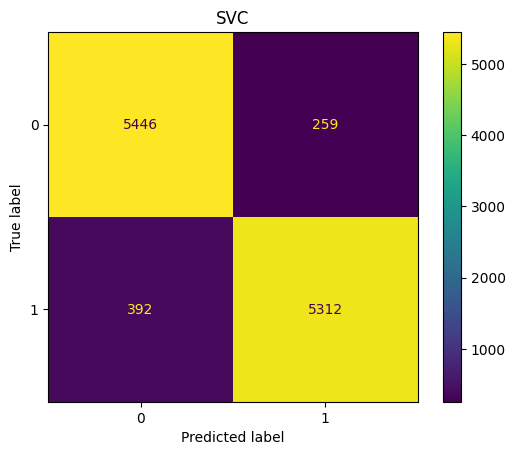

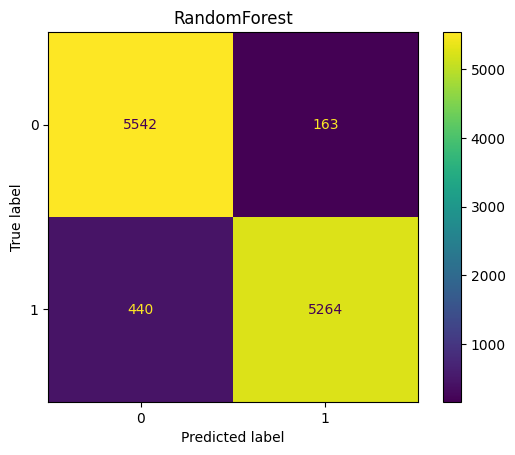

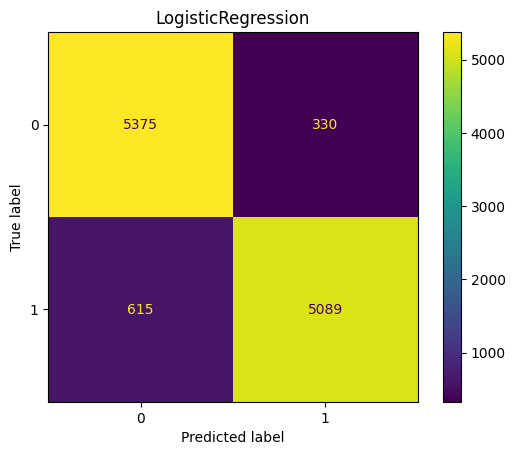

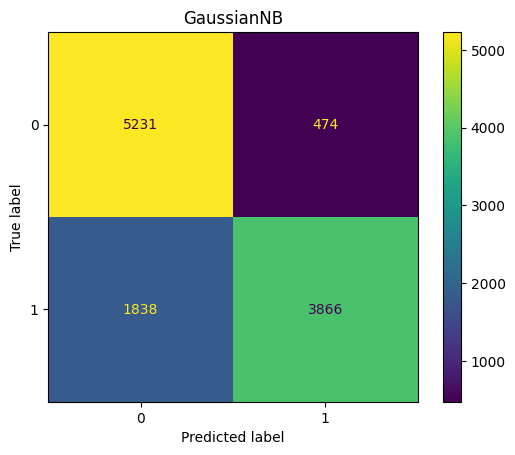

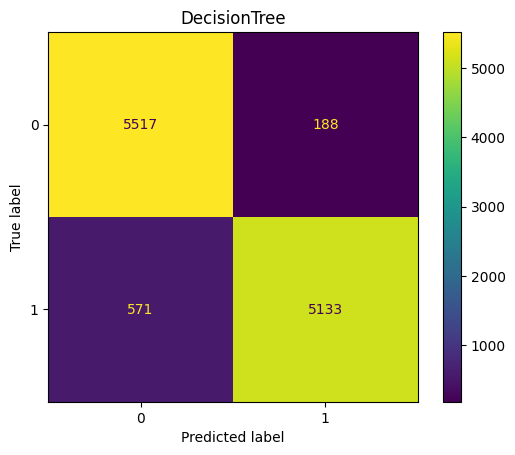

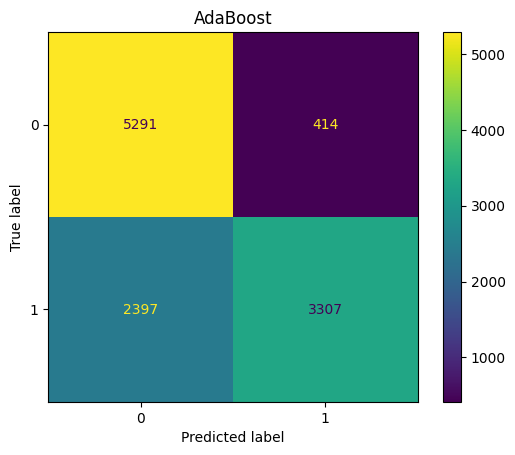

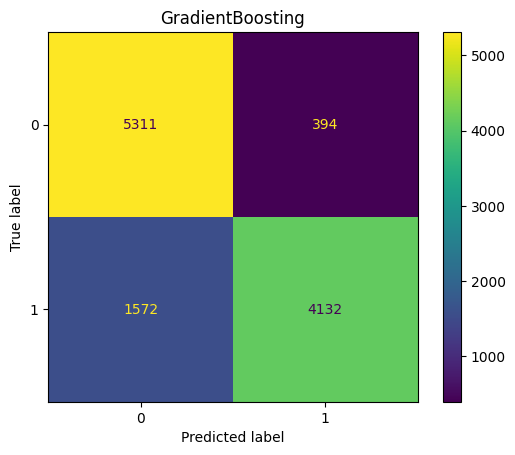

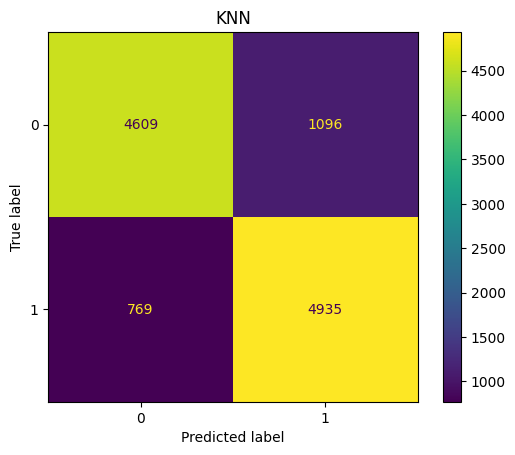

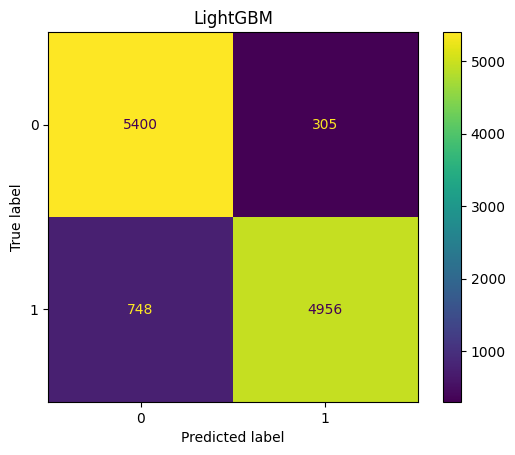

In [ ]:
for name, y_pred in y_preds.items():
    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()

    plt.title(name)
    plt.show()

In [ ]:
kappa_scores = {}

for name, y_pred in y_preds.items():
    kappa_scores[name] = cohen_kappa_score(y_test, y_pred)

for name, score in kappa_scores.items():
    print(f"{name} - Kappa: {score}\n")

SVC - Kappa: 0.8858793346728331

RandomForest - Kappa: 0.8942935277257834

LogisticRegression - Kappa: 0.8343405827892982

GaussianNB - Kappa: 0.5946974364792725

DecisionTree - Kappa: 0.8669463629695571

AdaBoost - Kappa: 0.5072161149202903

GradientBoosting - Kappa: 0.6553535628932246

KNN - Kappa: 0.673066764150442

LightGBM - Kappa: 0.8154076298315498



In [ ]:
error_rates = {}

for name, y_pred in y_preds.items():
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    taxa_erro = (fp + fn) / (tp + tn + fp + fn)

    error_rates[name] = taxa_erro

for name, error in error_rates.items():
    print(f"{name} - Taxa de Erro: {round(error, 4)}\n")

SVC - Taxa de Erro: 0.0571

RandomForest - Taxa de Erro: 0.0529

LogisticRegression - Taxa de Erro: 0.0828

GaussianNB - Taxa de Erro: 0.2026

DecisionTree - Taxa de Erro: 0.0665

AdaBoost - Taxa de Erro: 0.2464

GradientBoosting - Taxa de Erro: 0.1723

KNN - Taxa de Erro: 0.1635

LightGBM - Taxa de Erro: 0.0923



In [ ]:
# Converter métricas adicionais em DataFrames
df_kappa = pd.DataFrame.from_dict(kappa_scores, orient='index', columns=['Kappa'])
df_taxa_erro = pd.DataFrame.from_dict(error_rates, orient='index', columns=['Taxa_Erro'])

# Garantir que o índice é o nome do modelo
df_models_results = df_models_results.set_index("Model")

# Juntar tudo num único DataFrame
df_resultados = (
    df_models_results
    .join(df_kappa)
    .join(df_taxa_erro)
)

# Ordenar pelo F1 (ou outra métrica que quiseres)
df_resultados = df_resultados.sort_values(by="F1", ascending=False)

print(df_resultados)


                         Acc      Prec       Rec        F1     Kappa  Taxa_Erro
Model                                                                          
RandomForest        0.947147  0.948204  0.947147  0.947116  0.894294   0.052853
SVC                 0.942940  0.943181  0.942940  0.942932  0.885879   0.057060
DecisionTree        0.933474  0.935436  0.933474  0.933398  0.866946   0.066526
LogisticRegression  0.917171  0.918214  0.917171  0.917119  0.834341   0.082829
LightGBM            0.907704  0.910178  0.907704  0.907565  0.815408   0.092296
KNN                 0.836533  0.837643  0.836533  0.836399  0.673067   0.163467
GradientBoosting    0.827680  0.842273  0.827680  0.825821  0.655354   0.172320
GaussianNB          0.797353  0.815381  0.797353  0.794412  0.594697   0.202647
AdaBoost            0.753616  0.788469  0.753616  0.745936  0.507216   0.246384


Após a avaliação dos algoritmos, conclui-se que o modelo Random Forest é o mais robusto. Este modelo não só liderou todas as métricas utilizadas (Exatidão, Precisão, Recall, F1-Score e índice Kappa), como também apresentou a menor taxa de erro de todo o conjunto de teste.

In [ ]:
df_resultados.to_csv("resultados_modelos_base.csv", index=True, encoding="utf-8")

#**8. Classificação de novo comentário**

In [ ]:
### --- NOVOS COMENTÁRIOS: --- ###

uploaded = files.upload()

novos_comentarios = pd.read_csv(io.BytesIO(uploaded['Comentarios.csv']), sep=';')

Saving Comentarios.csv to Comentarios.csv


In [ ]:
novos_comentarios.head()

,Comentarios_Novos,Sentiment
0,This app is a true paragon.,Positive
1,The interface remains totally execrable.,Negative
2,A very pedestrian and basic design.,Neutral
3,Simply effulgent and highly efficient!,Positive
4,Navigation is inimical to usage.,Negative


## **8.1. Remoção de elementos neutros**

In [ ]:
novos_comentarios = novos_comentarios[novos_comentarios['Sentiment'] != "Neutral"].reset_index(drop=True)

In [ ]:
novos_comentarios.head()

,Comentarios_Novos,Sentiment
0,This app is a true paragon.,Positive
1,The interface remains totally execrable.,Negative
2,Simply effulgent and highly efficient!,Positive
3,Navigation is inimical to usage.,Negative


## **8.1. Tratamento de Chatwords**

In [ ]:
chatwords_dict = {
    "AFAIK": "As Far As I Know",
    "AFK": "Away From Keyboard",
    "ASAP": "As Soon As Possible",
    "LOL": "laugh out loud",
    "BTW": "By The Way",
    "BRB": "Be Right Back",
    "OMG": "Oh My God",
    "IDK": "I don't know",
    "FYI": "For Your Information",
    "TYT": "Take Your Time",
    "THX": "Thanks",
    "SPK": "Speak"
}

# Função para expandir chatwords
def expand_chatwords(text):
    for chatword, significado in chatwords_dict.items():
        text = text.replace(chatword, significado)
        text = text.replace(chatword.lower(), significado)
    return text

# Aplicar aos comentários
novos_comentarios["Comentarios_Novos"] = (
    novos_comentarios["Comentarios_Novos"]
    .apply(expand_chatwords)
)

# Mostrar resultado
display(novos_comentarios[["Comentarios_Novos"]].head())

,Comentarios_Novos
0,This app is a true paragon.
1,The interface remains totally execrable.
2,Simply effulgent and highly efficient!
3,Navigation is inimical to usage.


## **8.2. Remover elementos HTML**

In [ ]:
# Remover HTML dos comentários
novos_comentarios["Comentarios_Novos"] = (
    novos_comentarios["Comentarios_Novos"]
    .apply(unescape)
    .str.replace(r'<.*?>', '', regex=True)
)

# Mostrar resultado
display(novos_comentarios[["Comentarios_Novos"]].head())

,Comentarios_Novos
0,This app is a true paragon.
1,The interface remains totally execrable.
2,Simply effulgent and highly efficient!
3,Navigation is inimical to usage.


## **8.3. Remover URLs dos comentários**

In [ ]:
# Remover URLs dos comentários
novos_comentarios["Comentarios_Novos"] = (
    novos_comentarios["Comentarios_Novos"]
    .str.replace(r'http\S+|www\S+|https\S+', '', regex=True)
)

# Mostrar resultado
display(novos_comentarios[["Comentarios_Novos"]].head())

,Comentarios_Novos
0,This app is a true paragon.
1,The interface remains totally execrable.
2,Simply effulgent and highly efficient!
3,Navigation is inimical to usage.


## **8.4. Conversão para minúsculas**

In [ ]:
# Converter comentários para minúsculas
novos_comentarios["Comentarios_Novos"] = (
    novos_comentarios["Comentarios_Novos"]
    .str.lower()
)

# Mostrar resultado
display(novos_comentarios[["Comentarios_Novos"]].head())

,Comentarios_Novos
0,this app is a true paragon.
1,the interface remains totally execrable.
2,simply effulgent and highly efficient!
3,navigation is inimical to usage.


## **8.5. Expanção de contrações de palavras**

In [ ]:
# Expandir contrações
novos_comentarios["Comentarios_Novos"] = (
    novos_comentarios["Comentarios_Novos"]
    .apply(contractions.fix)
)

# Mostrar resultado
display(novos_comentarios[["Comentarios_Novos"]].head())

,Comentarios_Novos
0,this app is a true paragon.
1,the interface remains totally execrable.
2,simply effulgent and highly efficient!
3,navigation is inimical to usage.


## **8.6. Tratamento de Emoticons**

In [ ]:
# Dicionário de emoticons e respetivos significados
emoticons_dict = {
    ":-)": "happy face",
    ":)": "happy face",
    ":-(": "sad face",
    ":(": "sad face",
    ":-D": "laughing face",
    ":D": "laughing face",
    ";-)": "winking face",
    ";)": "winking face",
    ":-/": "confused face",
    ":/": "confused face"
}

# Função para substituir emoticons
def replace_emoticons(text):
    for emoticon, significado in emoticons_dict.items():
        text = text.replace(emoticon, significado)
    return text

# Aplicar aos comentários
novos_comentarios["Comentarios_Novos"] = (
    novos_comentarios["Comentarios_Novos"]
    .apply(replace_emoticons)
)

# Mostrar resultado
display(novos_comentarios[["Comentarios_Novos"]].head())

,Comentarios_Novos
0,this app is a true paragon.
1,the interface remains totally execrable.
2,simply effulgent and highly efficient!
3,navigation is inimical to usage.


## **8.7. Tratamento de Emojis**

In [ ]:
# Converter emojis em texto
novos_comentarios["Comentarios_Novos"] = (
    novos_comentarios["Comentarios_Novos"]
    .apply(emoji.demojize)
)

# Mostrar resultado
display(novos_comentarios[["Comentarios_Novos"]].head())

,Comentarios_Novos
0,this app is a true paragon.
1,the interface remains totally execrable.
2,simply effulgent and highly efficient!
3,navigation is inimical to usage.


## **8.8. Remoção da pontuação**

In [ ]:
# Remover pontuação
novos_comentarios["Comentarios_Novos"] = (
    novos_comentarios["Comentarios_Novos"]
    .apply(lambda x: x.translate(str.maketrans('', '', string.punctuation)))
)

# Mostrar resultado
display(novos_comentarios[["Comentarios_Novos"]].head())

,Comentarios_Novos
0,this app is a true paragon
1,the interface remains totally execrable
2,simply effulgent and highly efficient
3,navigation is inimical to usage


## **8.9. Tratamento da negação**

In [ ]:
# Função para tratar negação com antónimos
def handle_negation(text):
    tokens = word_tokenize(str(text))
    resultado = []
    skip = False

    # Palavras de negação
    negations = ['not', 'no', 'cannot']

    for i in range(len(tokens)):
        if skip:
            skip = False
            continue

        # Se for negação + palavra seguinte
        if tokens[i] in negations and i + 1 < len(tokens):
            antonym = get_antonym(tokens[i + 1])
            resultado.append(antonym)
            skip = True
        else:
            resultado.append(tokens[i])

    return ' '.join(resultado)

# Aplicar ao CSV
novos_comentarios["Comentarios_Novos"] = (
    novos_comentarios["Comentarios_Novos"]
    .apply(handle_negation)
)

# Mostrar resultado
display(novos_comentarios[["Comentarios_Novos"]].head())

,Comentarios_Novos
0,this app is a true paragon
1,the interface remains totally execrable
2,simply effulgent and highly efficient
3,navigation is inimical to usage


## **8.10. Remoção de StopWords**

In [ ]:
# Remover stopwords
novos_comentarios["Comentarios_Novos"] = (
    novos_comentarios["Comentarios_Novos"]
    .apply(lambda text: ' '.join(
        [word for word in word_tokenize(str(text)) if word not in stop_words]
    ))
)

# Mostrar resultado
display(novos_comentarios[["Comentarios_Novos"]].head())

,Comentarios_Novos
0,app true paragon
1,interface remains totally execrable
2,simply effulgent highly efficient
3,navigation inimical usage


## **8.11. Lematização**

In [ ]:
# Aplicar lematização
novos_comentarios["Comentarios_Novos"] = (
    novos_comentarios["Comentarios_Novos"]
    .apply(lambda text: ' '.join(
        [lemmatizer.lemmatize(word) for word in word_tokenize(str(text))]
    ))
)

# Mostrar resultado
display(novos_comentarios[["Comentarios_Novos"]].head())

,Comentarios_Novos
0,app true paragon
1,interface remains totally execrable
2,simply effulgent highly efficient
3,navigation inimical usage


## **8.12. Classificação do Novo Comentário**

In [ ]:
# 1) Transformar o texto com o MESMO TF-IDF do treino
matriz_tfidf_novo = tfidf_vectorizer.transform(novos_comentarios["Comentarios_Novos"])

print("Matriz TF-IDF do novo comentário:", matriz_tfidf_novo.shape)

# 2) Aplicar a MESMA seleção de features (SelectKBest) usada no treino
matriz_novos_comentarios = selector.transform(matriz_tfidf_novo)

print("Matriz final (features seleccionadas) do novo comentário:", matriz_novos_comentarios.shape)

Matriz TF-IDF do novo comentário: (4, 8289)
Matriz final (features seleccionadas) do novo comentário: (4, 1000)


In [ ]:
previsoes = pd.DataFrame()

for nome_modelo, model in models.items():
    # O único que PRECISA de array densa é o GaussianNB.
    # Os outros usam a matriz esparsa original (o que também evita erros no LightGBM)
    if nome_modelo == "GaussianNB":
        X_input = matriz_novos_comentarios.toarray()
    else:
        X_input = matriz_novos_comentarios

    previsoes[nome_modelo] = model.predict(X_input)

# Juntar ao dataset original
resultado_final = pd.concat([novos_comentarios, previsoes], axis=1)

display(resultado_final.head())

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Comentarios_Novos,Sentiment,SVC,RandomForest,LogisticRegression,GaussianNB,DecisionTree,AdaBoost,GradientBoosting,KNN,LightGBM
0,app true paragon,Positive,Positive,Positive,Positive,Positive,Positive,Negative,Negative,Positive,Positive
1,interface remains totally execrable,Negative,Negative,Positive,Negative,Negative,Positive,Negative,Negative,Negative,Negative
2,simply effulgent highly efficient,Positive,Positive,Positive,Positive,Positive,Positive,Negative,Negative,Positive,Positive
3,navigation inimical usage,Negative,Positive,Positive,Positive,Positive,Positive,Negative,Negative,Positive,Negative


- O modelo com maior assertividade foi o LightGBM, sendo o único a alcançar uma taxa de acerto de 100% ao identificar perfeitamente tanto os dois comentários positivos como os dois negativos;

- Em seguida, temos o SVC, Logistic Regression, GuassianNB e o KNN, que apenas falharam no comentário "navigation inimical usage", onde classificaram o mesmo incorretamente como positivo;

- De um lado, temos o AdaBoost e GradientBoosting que classificaram os comentários positivos como sendo negativos;

- Por outro lado, temos o  RandomForest e DecisionTree que classificaram os comentários negativos como sendo positivos;

Assim sendo, o modelo RandomForest, apesar de ter tido os melhores resultados nas métricas vistas anteriormente, acabou por falhar na prática. Ao avaliar os novos comentários, o modelo classificou todos os comentários negativos como sendo positivos. Isto prova que o RandomForest sofreu de overfitting (sobreajustamento), ou seja, ajustou-se excessivamente aos dados de treino, o que comprometeu a sua capacidade de generalização e o impediu de classificar novos comentários.

Por esse motivo, decidímos prosseguir com o modelo LightGBM, uma vez que apresentou resultados bastantes consistentes nas métricas de avaliação e foi o único modelo a classificar corretamente todos os novos comentários.

# **9. Comparação com os resultados dos LLMs**

In [ ]:
uploaded = files.upload()

resultados_models = pd.read_csv(io.BytesIO(uploaded['resultados_modelos_base.csv']), sep=',')
resultados_distilbert = pd.read_csv(io.BytesIO(uploaded['DistilBERT_results.csv']), sep=',')
resultados_distilgpt2 = pd.read_csv(io.BytesIO(uploaded['DistilGPT2_results.csv']), sep=',')
resultados_roberta = pd.read_csv(io.BytesIO(uploaded['RoBERTa_results.csv']), sep=',')

Saving DistilBERT_results.csv to DistilBERT_results.csv
Saving DistilGPT2_results.csv to DistilGPT2_results.csv
Saving resultados_modelos_base.csv to resultados_modelos_base.csv
Saving RoBERTa_results.csv to RoBERTa_results.csv


In [ ]:
analise_final = pd.concat([
    resultados_models,
    resultados_distilbert,
    resultados_distilgpt2,
    resultados_roberta
], axis=0, ignore_index=True)

analise_final

,Model,Acc,Prec,Rec,F1,Kappa,Taxa_Erro
0,RandomForest,0.947147,0.948204,0.947147,0.947116,0.894294,0.052853
1,SVC,0.942940,0.943181,0.942940,0.942932,0.885879,0.057060
2,DecisionTree,0.933474,0.935436,0.933474,0.933398,0.866946,0.066526
3,LogisticRegression,0.917171,0.918214,0.917171,0.917119,0.834341,0.082829
4,LightGBM,0.907704,0.910178,0.907704,0.907565,0.815408,0.092296
5,KNN,0.836533,0.837643,0.836533,0.836399,0.673067,0.163467
6,GradientBoosting,0.827680,0.842273,0.827680,0.825821,0.655354,0.172320
7,GaussianNB,0.797353,0.815381,0.797353,0.794412,0.594697,0.202647
8,AdaBoost,0.753616,0.788469,0.753616,0.745936,0.507216,0.246384
9,DistilBERT,0.966532,0.966886,0.966532,0.966662,0.912860,0.033468


Na análise dos resultados apresentados, o DistilBERT obteve melhores valores em todas as métricas de avaliação, atingindo uma Acurácia (Acc) de 0.9665, um F1-Score de 0.9667, um Kappa de 0.9129 e a menor Taxa de Erro (0.0335). Logo a seguir, temos o RoBERTa e o DistilGPT2, que também apresentam valores bastante altos, com Acurácias de 0.9554 e 0.9513, e F1-Scores de 0.9557 e 0.9516, respetivamente.

Contudo, embora DistilBERT apresente os resultados mais elevados, observados que o modelo está a sofrer overfitting. Assim, consideramos o LightGBM o melhor modelo para este trabalho. Este modelo demonstra ser uma solução mais equilibrada para lidar com novos dados, apesar de apresentar métricas inferiores, com uma acurácia de 0.9077, um F1-score de 0.9076, um Kappa de 0.8154 e uma Taxa de Erro de 0.0923.

# **10. eXplainable AI**

Aplicaremos o XAI ao LightGBM e ao DistilBERT, sendo que ao segundo aplicaremos no documento notebook correspondente.

In [ ]:
!pip install shap -q

A gerar gráfico global SHAP...
A gerar gráfico global SHAP...


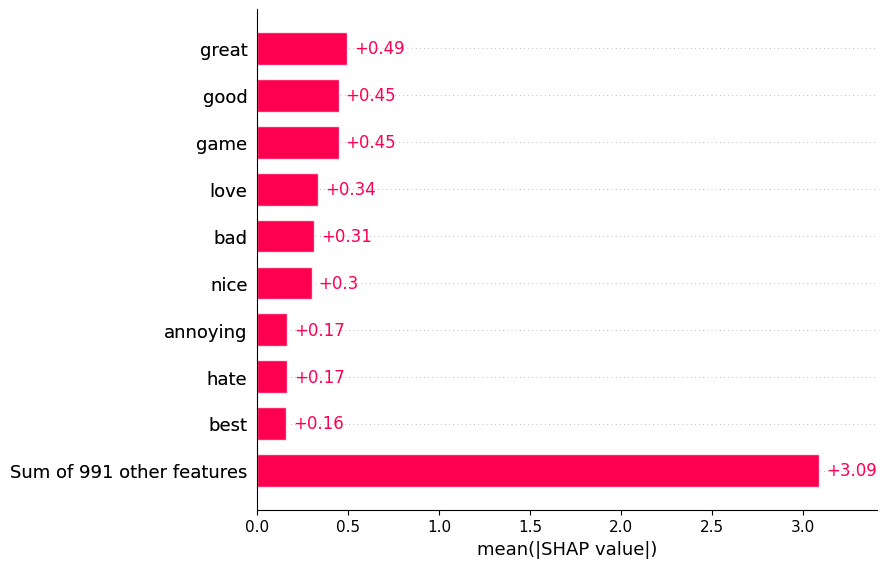

In [ ]:
# ============================
# EXPLAINABLE AI - SHAP
# ============================

classifier = models["LightGBM"]

# 1. Criar o Explainer usando a API padrão (passando os dados de treino normais)
explainer = shap.Explainer(classifier, X_train_sel.toarray())

# 2. Selecionar a amostra do conjunto de teste
X_sample = X_test_sel[:100].toarray()

# 3. Calcular os SHAP values usando a API nova (chama o explainer diretamente)
shap_values = explainer(X_sample)

if 'bestfeatures' in locals() or 'bestfeatures' in globals():
    shap_values.feature_names = bestfeatures

print("A gerar gráfico global SHAP...")


# 4. Calcular os SHAP values
shap_values = explainer(X_sample)

if 'bestfeatures' in locals() or 'bestfeatures' in globals():
    shap_values.feature_names = bestfeatures

print("A gerar gráfico global SHAP...")

if len(shap_values.shape) == 3:
    shap_plots_values = shap_values[:, :, 1]
else:
    shap_plots_values = shap_values

# 5. Gerar o gráfico
shap.plots.bar(shap_plots_values)

In [ ]:
# ==========================================================
# TOP FEATURES MAIS IMPORTANTES
# ==========================================================

feature_names = bestfeatures

if len(shap_values.shape) == 3:
    mean_abs_shap = np.abs(shap_values[:, :, 1].values).mean(axis=0)
else:

    mean_abs_shap = np.abs(shap_values.values).mean(axis=0)

importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': mean_abs_shap
})

importance_df = importance_df.sort_values(
    by='importance',
    ascending=False
)

print("\nTop 20 palavras mais importantes:\n")
print(importance_df.head(20).to_string(index=False))


Top 20 palavras mais importantes:

     feature  importance
       great    0.494877
        good    0.448145
        game    0.447735
        love    0.336283
         bad    0.313576
        nice    0.299143
    annoying    0.166074
        hate    0.165786
        best    0.161227
       worst    0.159058
        free    0.136663
disappointed    0.113204
        easy    0.108774
        slow    0.102290
        many    0.096849
     useless    0.094195
      better    0.093213
         fun    0.083592
  impossible    0.077241
   excellent    0.072763


In [ ]:
# ==========================================================
#  GUARDAR RESULTADOS
# ==========================================================

importance_df.to_csv(
    "shap_feature_importance.csv",
    index=False
)

print("Ficheiro guardado:")
print("shap_feature_importance.csv")

Ficheiro guardado:
shap_feature_importance.csv



 A ANALISAR: "great finding place take right door step place want go worked great warsaw aire"

A gerar explicação SHAP...



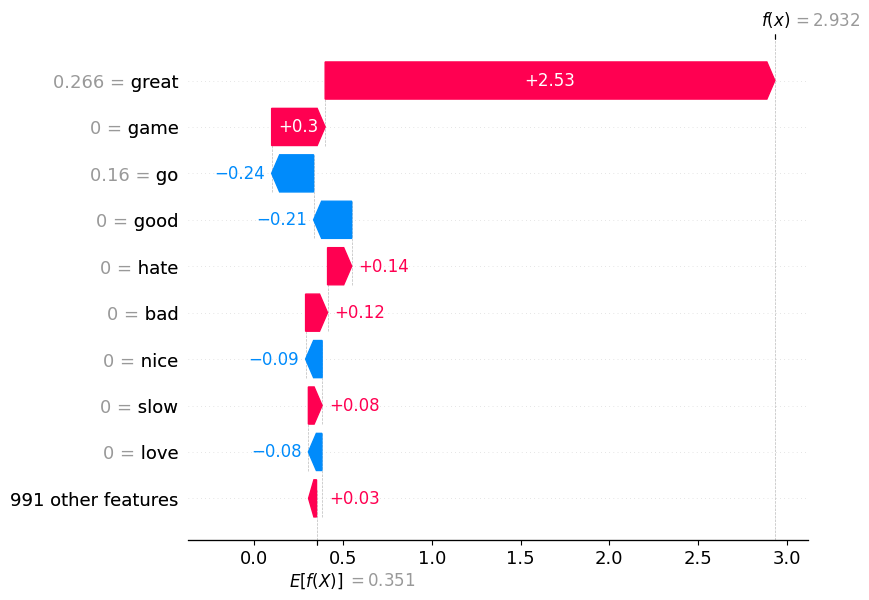


TOP PALAVRAS MAIS IMPORTANTES:

great ---> impacto SHAP = 2.5330
game ---> impacto SHAP = 0.3014
go ---> impacto SHAP = -0.2364
good ---> impacto SHAP = -0.2146
hate ---> impacto SHAP = 0.1360
bad ---> impacto SHAP = 0.1237
nice ---> impacto SHAP = -0.0932
slow ---> impacto SHAP = 0.0775
love ---> impacto SHAP = -0.0763
annoying ---> impacto SHAP = 0.0742

EXPLICAÇÃO AUTOMÁTICA:

A palavra 'great' teve influência POSITIVA na classificação.
A palavra 'game' teve influência POSITIVA na classificação.
A palavra 'go' teve influência NEGATIVA na classificação.
A palavra 'good' teve influência NEGATIVA na classificação.
A palavra 'hate' teve influência POSITIVA na classificação.
A palavra 'bad' teve influência POSITIVA na classificação.
A palavra 'nice' teve influência NEGATIVA na classificação.
A palavra 'slow' teve influência POSITIVA na classificação.
A palavra 'love' teve influência NEGATIVA na classificação.
A palavra 'annoying' teve influência POSITIVA na classificação.

 A ANALISAR: 

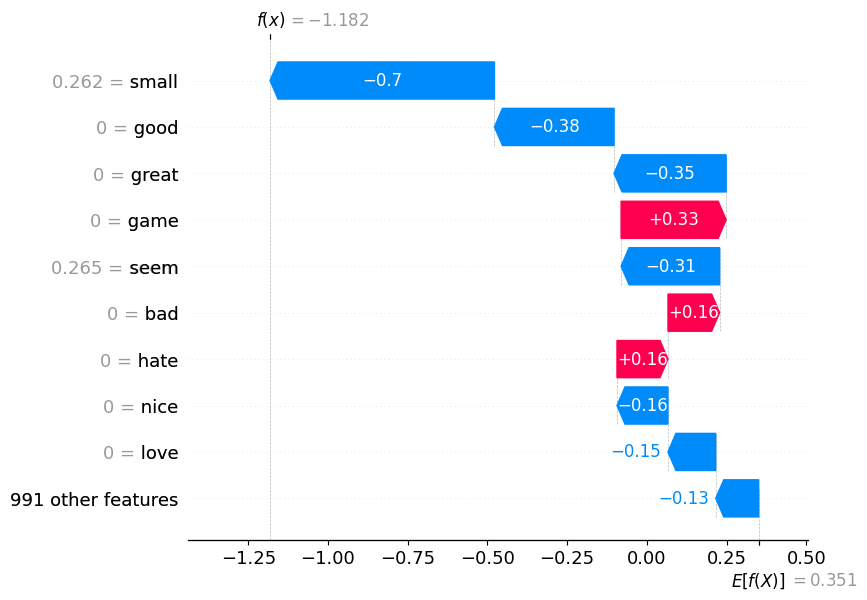


TOP PALAVRAS MAIS IMPORTANTES:

small ---> impacto SHAP = -0.7038
good ---> impacto SHAP = -0.3751
great ---> impacto SHAP = -0.3516
game ---> impacto SHAP = 0.3295
seem ---> impacto SHAP = -0.3091
bad ---> impacto SHAP = 0.1620
hate ---> impacto SHAP = 0.1599
nice ---> impacto SHAP = -0.1598
love ---> impacto SHAP = -0.1499
best ---> impacto SHAP = -0.1193

EXPLICAÇÃO AUTOMÁTICA:

A palavra 'small' teve influência NEGATIVA na classificação.
A palavra 'good' teve influência NEGATIVA na classificação.
A palavra 'great' teve influência NEGATIVA na classificação.
A palavra 'game' teve influência POSITIVA na classificação.
A palavra 'seem' teve influência NEGATIVA na classificação.
A palavra 'bad' teve influência POSITIVA na classificação.
A palavra 'hate' teve influência POSITIVA na classificação.
A palavra 'nice' teve influência NEGATIVA na classificação.
A palavra 'love' teve influência NEGATIVA na classificação.
A palavra 'best' teve influência NEGATIVA na classificação.

 A ANALISAR:

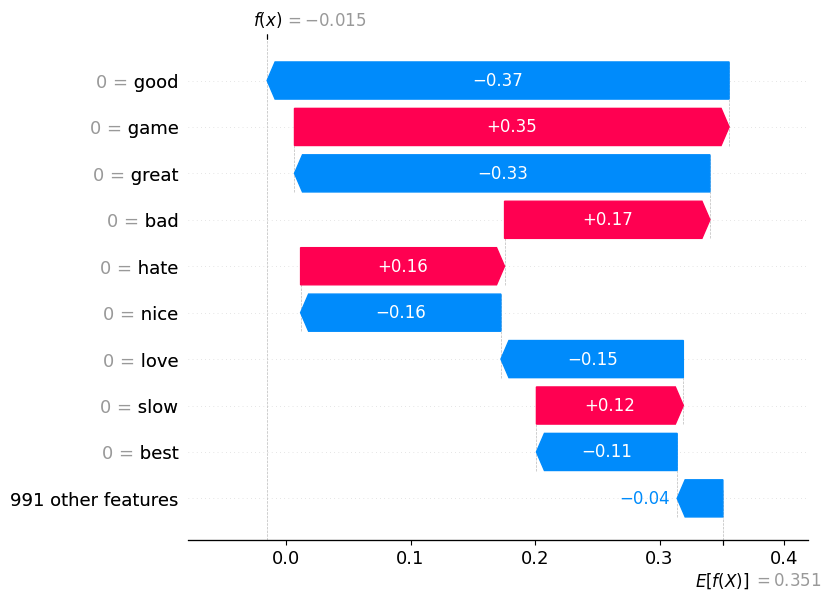


TOP PALAVRAS MAIS IMPORTANTES:

good ---> impacto SHAP = -0.3711
game ---> impacto SHAP = 0.3491
great ---> impacto SHAP = -0.3338
bad ---> impacto SHAP = 0.1650
hate ---> impacto SHAP = 0.1638
nice ---> impacto SHAP = -0.1609
love ---> impacto SHAP = -0.1465
slow ---> impacto SHAP = 0.1180
best ---> impacto SHAP = -0.1131
fun ---> impacto SHAP = -0.0950

EXPLICAÇÃO AUTOMÁTICA:

A palavra 'good' teve influência NEGATIVA na classificação.
A palavra 'game' teve influência POSITIVA na classificação.
A palavra 'great' teve influência NEGATIVA na classificação.
A palavra 'bad' teve influência POSITIVA na classificação.
A palavra 'hate' teve influência POSITIVA na classificação.
A palavra 'nice' teve influência NEGATIVA na classificação.
A palavra 'love' teve influência NEGATIVA na classificação.
A palavra 'slow' teve influência POSITIVA na classificação.
A palavra 'best' teve influência NEGATIVA na classificação.
A palavra 'fun' teve influência NEGATIVA na classificação.


In [ ]:
# ==========================================================
# Comentário positivo e negativo do df_final e comentário extraído do CSV
# ==========================================================

texto_positivo = "great finding place take right door step place want go worked great warsaw aire"
texto_negativo = "track food linked since fitness food pound may seem small big"
texto_novo     = "interface remains totally execrable"

todas_as_frases = [texto_positivo, texto_negativo, texto_novo]

# ==========================================================
# O LOOP QUE ANALISA AS 3 FRASES AUTOMATICAMENTE
# ==========================================================

for frase_escolhida in todas_as_frases:
    print("\n" + "="*70)
    print(f" A ANALISAR: \"{frase_escolhida}\"")
    print("="*70)

    # Pré-processamento do texto
    processed_frase = frase_escolhida.lower()
    processed_frase = contractions.fix(processed_frase)
    processed_frase = emoji.demojize(processed_frase)
    processed_frase = processed_frase.translate(str.maketrans('', '', string.punctuation))
    processed_frase = handle_negation(processed_frase)
    processed_frase = ' '.join([word for word in word_tokenize(processed_frase) if word not in stop_words])
    processed_frase = ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(processed_frase)])

    matriz_novo_comentario_tfidf = tfidf_vectorizer.transform([processed_frase])
    matriz_novo_comentario = selector.transform(matriz_novo_comentario_tfidf).toarray()

    # ==========================================================
    # CALCULAR SHAP VALUES (Adaptado para LightGBM)
    # ==========================================================

    shap_explanation = explainer(matriz_novo_comentario)

    shap_explanation.feature_names = bestfeatures

    shap_values_for_plot = shap_explanation[0]

    # ==========================================================
    # GERAR EXPLICAÇÃO VISUAL
    # ==========================================================

    print("\nA gerar explicação SHAP...\n")

    shap.plots.waterfall(shap_values_for_plot)

    # ==========================================================
    # MOSTRAR PALAVRAS MAIS IMPORTANTES
    # ==========================================================

    feature_names = bestfeatures

    valores = shap_explanation.values[0]

    indices = np.argsort(np.abs(valores))[::-1]

    print("\nTOP PALAVRAS MAIS IMPORTANTES:\n")

    for i in indices[:10]:
        if valores[i] != 0:
            palavra = feature_names[i]
            impacto = valores[i]
            print(f"{palavra} ---> impacto SHAP = {impacto:.4f}")

    # ==========================================================
    # EXPLICAÇÃO TEXTUAL AUTOMÁTICA
    # ==========================================================

    print("\nEXPLICAÇÃO AUTOMÁTICA:\n")

    for i in indices[:10]:
        if valores[i] != 0:
            palavra = feature_names[i]
            impacto = valores[i]

            if impacto > 0:
                direcao = "POSITIVA"
            else:
                direcao = "NEGATIVA"

            print(
                f"A palavra '{palavra}' "
                f"teve influência {direcao} "
                f"na classificação."
            )